# 03 · Financial EDA — markets, cross-domain signals, element costs, exposure and loss

The risk engine needs five financial ingredients. This notebook checks, for each, what the supplied data can and cannot support:

| Part | Data | Core question for the risk engine |
|---|---|---|
| **A** | DS2 commodity prices (8 × 2,869 days) | Are returns fat-tailed, clustered, seasonal, dependent? Which VaR/ES method is defensible? |
| **B** | DS4 cross-domain features ↔ DS2 | Does MQI / supply-disruption information predict returns or volatility? |
| **C** | DS5 element prices; DS1 coverage | Can element costs feed material-linked financial features? |
| **D** | DS3 exposure, DS6 losses | What do EAD (exposure) and LGD (loss severity) look like, and how heavy are the tails? |

Conventions: annualisation √252 (the convention that reproduces the supplied volatility columns, audit rule DS2-10); returns are log returns
(`daily_return`, verified against `ln(close_t/close_{t-1})` in the audit); forward-looking quantities are built only from future prices relative to a feature date and
sampled **without overlap** before testing, so p-values are not inflated by overlapping windows; multiple comparisons use Benjamini–Hochberg.
Nothing is removed or imputed; raw data are untouched.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats as sps
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))
from src.data import audit as A
from src.utils import stats as S

RAW, TAB, FIG = ROOT/"data/raw", ROOT/"outputs/tables", ROOT/"outputs/figures"
for p in (TAB, FIG): p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42
rng = np.random.default_rng(SEED)
KEY = {}   # key numeric findings, saved at the end

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

def note(key, value, text):
    """Record a computed finding (shown in the final summary and saved to CSV)."""
    KEY[key] = {"value": value, "meaning": text}

from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from itertools import combinations

dfs = A.load_csvs(RAW)
d2 = dfs["DS2"].sort_values(["commodity", "date"]).reset_index(drop=True); d3, d4, d5, d6, d1 = dfs["DS3"], dfs["DS4"], dfs["DS5"], dfs["DS6"], dfs["DS1"]
COMS = list(d2.commodity.unique()); ANN = 252
px  = d2.pivot(index="date", columns="commodity", values="close")[COMS]
ret = d2.pivot(index="date", columns="commodity", values="daily_return")[COMS]
chk = (np.log(px).diff() - ret).abs().max().max()
print(f"{len(COMS)} commodities x {len(px)} dates | supplied daily_return vs ln(close ratio): max abs diff = {chk:.2e}")

8 commodities x 2869 dates | supplied daily_return vs ln(close ratio): max abs diff = 5.00e-07


# PART A — DS2 commodity markets
## A1 · Price paths and return summary
*Question: how do the eight series behave over the decade, and are daily returns plausibly normal?*

,start,end,CAGR,ann_log_return,ann_vol,skew,excess_kurtosis,min_1d,max_1d,JarqueBera_p,return_per_unit_vol
commodity,,,,,,,,,,,
Aluminium,2114.7552,2327.6289,0.0088,0.0084,0.2418,0.0622,-0.0342,-0.0464,0.0537,0.3665,0.0349
Cobalt_Index,80.7516,130.9860,0.0450,0.0425,0.3180,-0.1020,0.0090,-0.0655,0.0628,0.0830,0.1336
Copper,3.1271,3.9109,0.0206,0.0197,0.2522,-0.0103,-0.0763,-0.0529,0.0631,0.6759,0.0779
Iron_Ore,95.7888,73.8947,-0.0233,-0.0228,0.3243,-0.0827,0.1302,-0.0824,0.0707,0.0736,-0.0703
Lithium_ETF,45.2410,87.1302,0.0614,0.0576,0.3981,-0.0593,0.1410,-0.1100,0.0817,0.1371,0.1446
Nickel,15223.8369,21909.7229,0.0337,0.0320,0.3428,-0.0161,-0.1352,-0.0714,0.0744,0.3058,0.0933
RareEarth_ETF,56.6552,48.9372,-0.0132,-0.0129,0.4374,-0.0720,0.0103,-0.1090,0.0867,0.2890,-0.0294
Steel_HRC,598.4254,523.3407,-0.0121,-0.0118,0.2876,-0.0362,0.0081,-0.0641,0.0643,0.7293,-0.0410


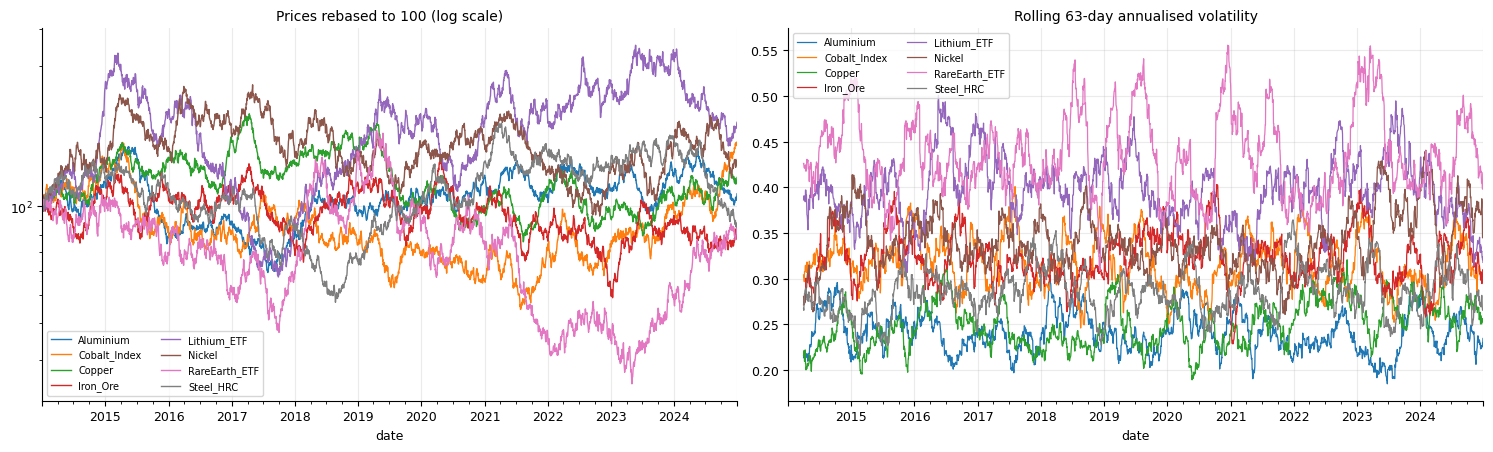

In [2]:
yrs = (px.index[-1] - px.index[0]).days / 365.25
perf = pd.DataFrame({"start": px.iloc[0], "end": px.iloc[-1], "CAGR": (px.iloc[-1] / px.iloc[0]) ** (1 / yrs) - 1, "ann_log_return": ret.mean() * ANN,
                     "ann_vol": ret.std() * np.sqrt(ANN), "skew": ret.skew(), "excess_kurtosis": ret.kurt(), "min_1d": ret.min(), "max_1d": ret.max(),
                     "JarqueBera_p": [sps.jarque_bera(ret[c].dropna())[1] for c in COMS]})
perf["return_per_unit_vol"] = perf.ann_log_return / perf.ann_vol; perf = perf.round(4); perf.to_csv(TAB / "A1_commodity_performance.csv"); display(perf)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
(px / px.iloc[0] * 100).plot(ax=ax[0], logy=True, lw=1); ax[0].set_title("Prices rebased to 100 (log scale)"); ax[0].legend(ncol=2, fontsize=7)
(ret.rolling(63).std() * np.sqrt(ANN)).plot(ax=ax[1], lw=.9); ax[1].set_title("Rolling 63-day annualised volatility"); ax[1].legend(ncol=2, fontsize=7)
savefig("A1_prices_vol.png")
note("ds2_mean_ann_vol", float(perf.ann_vol.mean()), "mean annualised volatility across commodities")
note("ds2_max_abs_excess_kurtosis", float(perf.excess_kurtosis.abs().max()), "largest |excess kurtosis| of daily returns (0 = normal tails)")
note("ds2_JB_reject_count", int((perf.JarqueBera_p < 0.05).sum()), "commodities where normality is rejected (Jarque-Bera p<0.05), out of 8")

## A2 · Return distributions vs the normal
*Question: do the tails exceed what a normal distribution implies? This decides whether parametric (normal) VaR is acceptable or historical/stressed methods are required.*

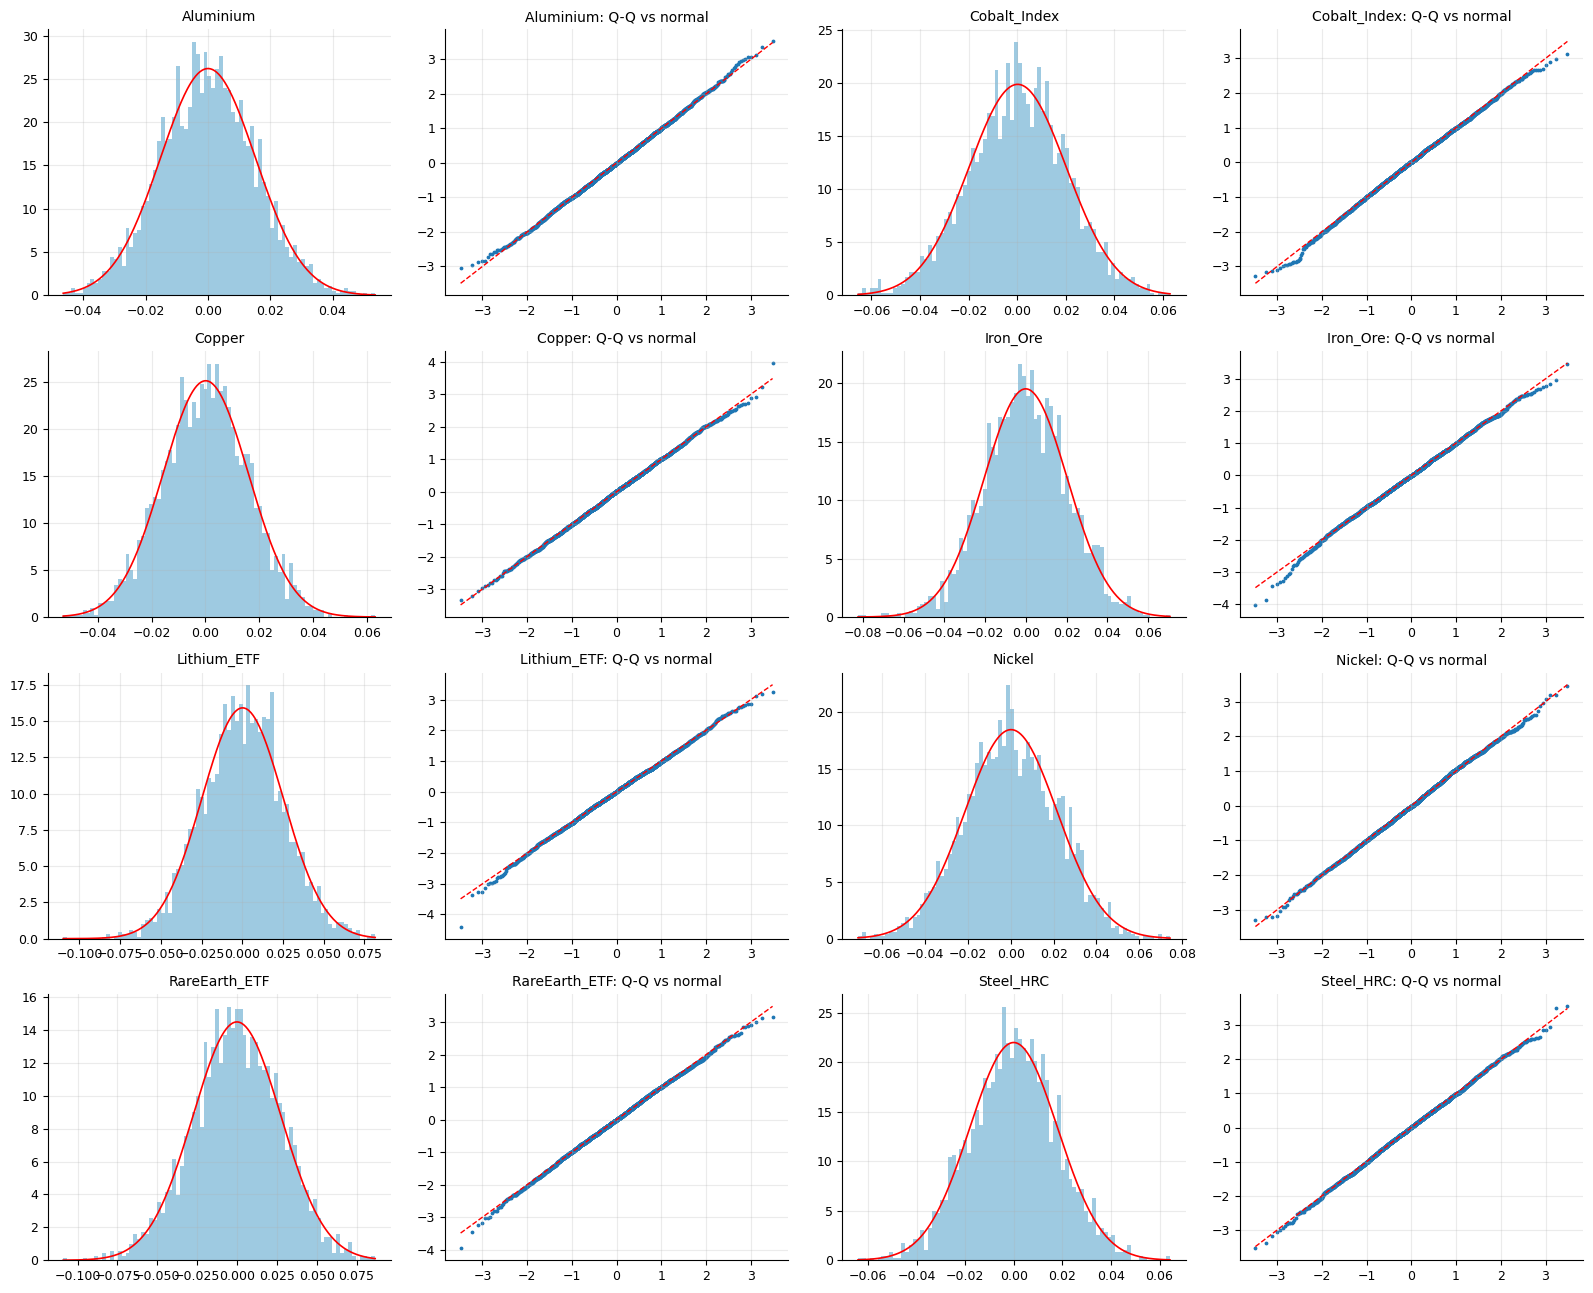

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for i, c in enumerate(COMS):
    a, b = axes[i // 2][(i % 2) * 2], axes[i // 2][(i % 2) * 2 + 1]; x = ret[c].dropna()
    a.hist(x, bins=80, density=True, color="#9ecae1"); xs = np.linspace(x.min(), x.max(), 300); a.plot(xs, sps.norm.pdf(xs, x.mean(), x.std()), "r", lw=1.2); a.set_title(c)
    (osm, osr), (sl, ic, _) = sps.probplot((x - x.mean()) / x.std(), dist="norm"); b.scatter(osm, osr, s=3); b.plot(osm, osm, "r--", lw=1); b.set_title(f"{c}: Q-Q vs normal")
savefig("A2_return_distributions.png")

## A3 · Volatility level and regimes
*Question: is volatility stable, or do regimes/structural breaks exist? Do all commodities share a common volatility regime?*

,min_annual_vol,max_annual_vol,max/min,Levene_p_across_years,Levene_p_first_vs_second_half,rolling63_max/min
Aluminium,0.2269,0.2607,1.1489,0.6314,0.7208,1.6083
Cobalt_Index,0.2946,0.3299,1.1198,0.7748,0.4566,1.6293
Copper,0.2300,0.2852,1.2403,0.0111,0.1021,1.6944
Iron_Ore,0.3009,0.3444,1.1447,0.9179,0.5681,1.7632
Lithium_ETF,0.3642,0.4393,1.2061,0.2097,0.0468,1.6329
Nickel,0.3066,0.3812,1.2432,0.0867,0.9120,1.6893
RareEarth_ETF,0.4183,0.4556,1.0891,0.7307,0.5350,1.7998
Steel_HRC,0.2705,0.2974,1.0993,0.8106,0.5411,1.6879


Mean pairwise correlation of rolling-vol paths across commodities (common vol regime?) = -0.017


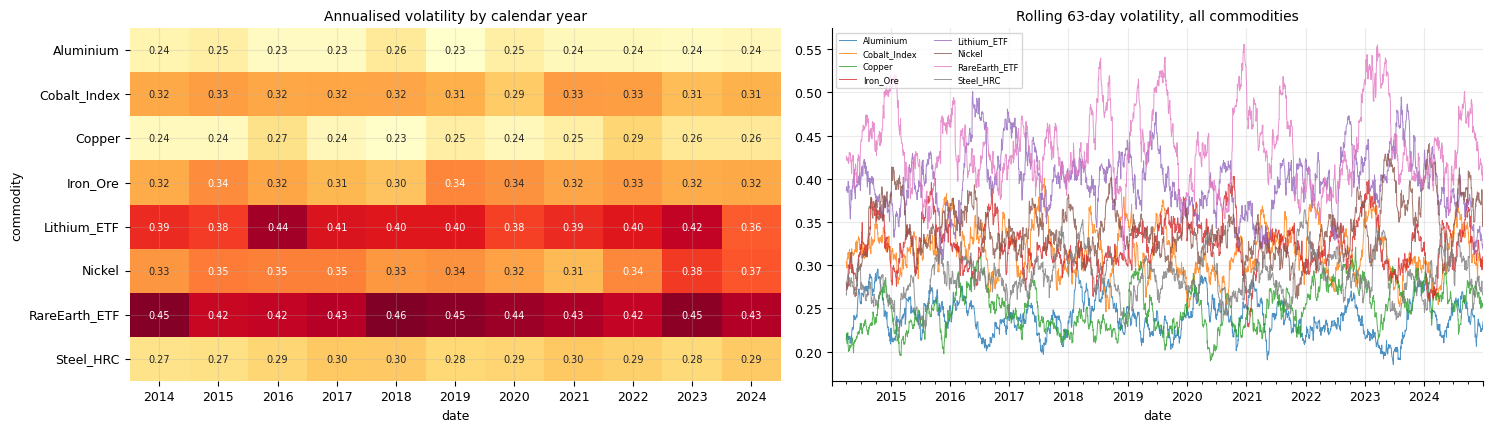

In [4]:
yv = ret.groupby(ret.index.year).std() * np.sqrt(ANN)
rv = ret.rolling(63).std() * np.sqrt(ANN)
lev = {c: sps.levene(*[g.dropna().values for _, g in ret[c].groupby(ret.index.year)]).pvalue for c in COMS}
half = {c: sps.levene(ret[c].dropna().iloc[:len(ret) // 2], ret[c].dropna().iloc[len(ret) // 2:]).pvalue for c in COMS}
vt = pd.DataFrame({"min_annual_vol": yv.min(), "max_annual_vol": yv.max(), "max/min": yv.max() / yv.min(), "Levene_p_across_years": pd.Series(lev),
                   "Levene_p_first_vs_second_half": pd.Series(half), "rolling63_max/min": rv.max() / rv.min()}).round(4); vt.to_csv(TAB / "A3_volatility_regimes.csv"); display(vt)
off = (lambda m: (m.values.sum() - len(m)) / (len(m) ** 2 - len(m)))(rv.dropna().corr())
print(f"Mean pairwise correlation of rolling-vol paths across commodities (common vol regime?) = {off:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
sns.heatmap(yv.T, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Annualised volatility by calendar year")
rv.plot(ax=ax[1], lw=.7, alpha=.8); ax[1].set_title("Rolling 63-day volatility, all commodities"); ax[1].legend(ncol=2, fontsize=6)
savefig("A3_volatility_regimes.png")
note("ds2_vol_max_over_min_annual", float((yv.max() / yv.min()).max()), "largest ratio of max to min annual volatility within a commodity")
note("ds2_levene_reject_count", int((pd.Series(lev) < 0.05).sum()), "commodities with significantly different variance across years (Levene p<0.05)")
note("ds2_common_vol_regime_corr", float(off), "mean pairwise correlation of rolling-vol series")

## A4 · Volatility clustering and autocorrelation
*Question: is there serial dependence in returns (momentum/mean reversion) or in squared returns (volatility clustering)? This decides whether GARCH/EWMA volatility scaling is justified.*

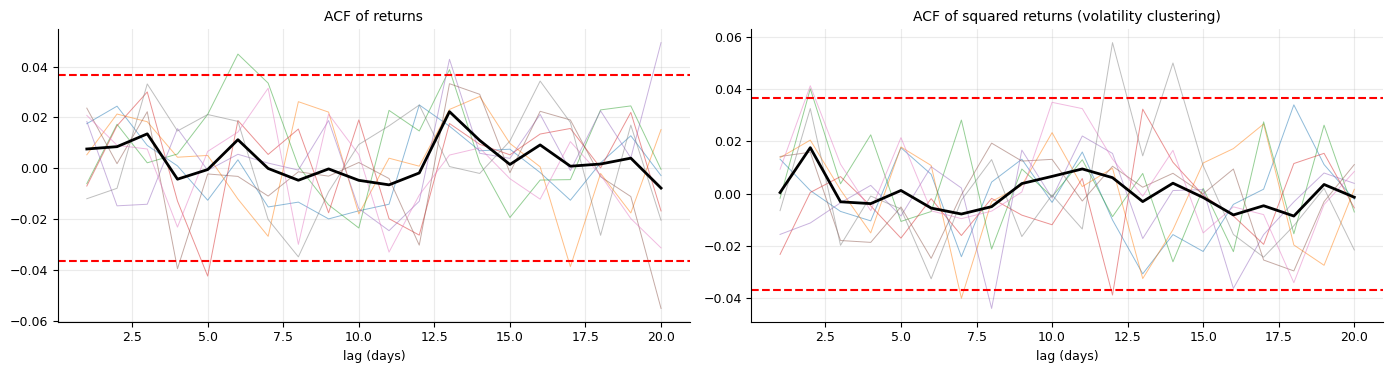

,lag1_autocorr,LjungBox_p_returns(10),LjungBox_p_squared(10),ARCH_LM_p(10),q_ret,q_sq,q_arch
Aluminium,0.0175,0.7771,0.9356,0.9330,0.9516,0.9516,0.9516
Cobalt_Index,0.0053,0.5073,0.4528,0.4258,0.9516,0.9516,0.9516
Copper,-0.0060,0.1936,0.4061,0.4382,0.9516,0.9516,0.9516
Iron_Ore,-0.0070,0.2301,0.9516,0.9466,0.9516,0.9516,0.9516
Lithium_ETF,0.0184,0.9094,0.6313,0.6402,0.9516,0.9516,0.9516
Nickel,0.0237,0.6332,0.7200,0.7569,0.9516,0.9516,0.9516
RareEarth_ETF,0.0208,0.3809,0.3606,0.3661,0.9516,0.9516,0.9516
Steel_HRC,-0.0120,0.2998,0.5620,0.5418,0.9516,0.9516,0.9516


In [5]:
lags = 20
acf_r  = pd.DataFrame({c: acf(ret[c].dropna(), nlags=lags, fft=True)[1:] for c in COMS}, index=range(1, lags + 1))
acf_r2 = pd.DataFrame({c: acf((ret[c].dropna()) ** 2, nlags=lags, fft=True)[1:] for c in COMS}, index=range(1, lags + 1))
T_ = len(ret) - 1; band = 1.96 / np.sqrt(T_)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, df_, t in zip(ax, (acf_r, acf_r2), ("ACF of returns", "ACF of squared returns (volatility clustering)")):
    df_.plot(ax=a, lw=.7, alpha=.5, legend=False); df_.mean(axis=1).plot(ax=a, color="k", lw=2, label="mean"); a.axhline(band, color="r", ls="--"); a.axhline(-band, color="r", ls="--"); a.set_title(t); a.set_xlabel("lag (days)")
savefig("A4_acf.png")
rows = {}
for c in COMS:
    x = ret[c].dropna()
    rows[c] = {"lag1_autocorr": x.autocorr(1), "LjungBox_p_returns(10)": acorr_ljungbox(x, lags=[10]).lb_pvalue.iloc[0],
               "LjungBox_p_squared(10)": acorr_ljungbox(x ** 2, lags=[10]).lb_pvalue.iloc[0], "ARCH_LM_p(10)": het_arch(x, nlags=10)[1]}
lb = pd.DataFrame(rows).T
allp = lb[["LjungBox_p_returns(10)", "LjungBox_p_squared(10)", "ARCH_LM_p(10)"]].values.ravel(); qq = S.bh_fdr(allp).reshape(-1, 3)
lb["q_ret"], lb["q_sq"], lb["q_arch"] = qq[:, 0], qq[:, 1], qq[:, 2]; lb = lb.round(4); lb.to_csv(TAB / "A4_serial_dependence.csv"); display(lb)
note("ds2_ljungbox_returns_reject", int((lb.q_ret < .05).sum()), "commodities with significant return autocorrelation (BH q<0.05), of 8")
note("ds2_ljungbox_squared_reject", int((lb.q_sq < .05).sum()), "commodities with significant volatility clustering in squared returns (BH q<0.05)")
note("ds2_arch_lm_reject", int((lb.q_arch < .05).sum()), "commodities where ARCH-LM rejects constant conditional variance (BH q<0.05)")
note("ds2_mean_abs_lag1_autocorr", float(lb.lag1_autocorr.abs().mean()), "mean |lag-1 autocorrelation| of daily returns")

## A5 · Stationarity, trend and seasonality
*Question: are price levels non-stationary (random-walk-like) while returns are stationary? Is there a drift, or calendar-month / weekday seasonality?*

,ADF_p_log_price(trend),ADF_p_returns,log_price_slope_per_year,slope_p,trend_R2
Aluminium,0.4314,0.0,0.0241,0.0,0.1682
Cobalt_Index,0.9499,0.0,-0.0246,0.0,0.1015
Copper,0.2693,0.0,-0.0308,0.0,0.2384
Iron_Ore,0.0289,0.0,-0.0278,0.0,0.2649
Lithium_ETF,0.6616,0.0,0.0589,0.0,0.2297
Nickel,0.0354,0.0,-0.0188,0.0,0.0904
RareEarth_ETF,0.7175,0.0,-0.0613,0.0,0.2491
Steel_HRC,0.8285,0.0,0.0316,0.0,0.1318


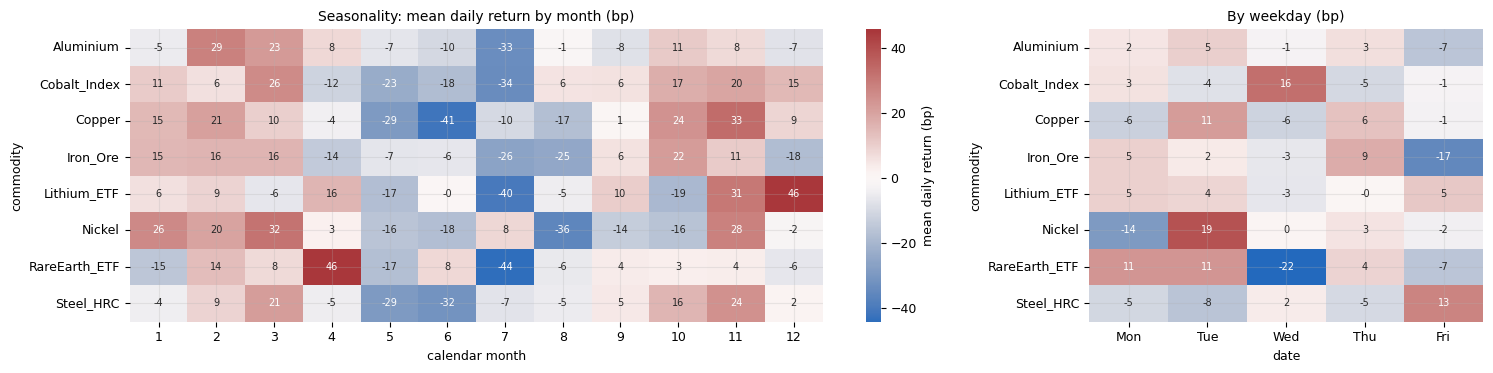

Kruskal p across calendar months: {'Aluminium': 0.004, 'Cobalt_Index': 0.032, 'Copper': 0.0, 'Iron_Ore': 0.041, 'Lithium_ETF': 0.02, 'Nickel': 0.008, 'RareEarth_ETF': 0.211, 'Steel_HRC': 0.008} | BH q<0.05: 4 of 8
Kruskal p across weekdays      : {'Aluminium': 0.635, 'Cobalt_Index': 0.683, 'Copper': 0.386, 'Iron_Ore': 0.29, 'Lithium_ETF': 0.925, 'Nickel': 0.131, 'RareEarth_ETF': 0.23, 'Steel_HRC': 0.395} | BH q<0.05: 0 of 8
Common seasonal pattern? mean pairwise correlation of the 8 month-profiles = 0.46 | amplitude (best minus worst month) = 48-90 bp/day | equal-weight average of all 8: Kruskal p across months = 8.3e-14
Worst/best calendar months of the equal-weight average (bp/day): {7: -23.3, 5: -18.2, 6: -14.8, 2: 15.5, 3: 16.2, 11: 19.8}


In [6]:
adf = pd.DataFrame({c: {"ADF_p_log_price(trend)": adfuller(np.log(px[c]), regression="ct", autolag="AIC")[1], "ADF_p_returns": adfuller(ret[c].dropna(), regression="c", autolag="AIC")[1]} for c in COMS}).T
tt = np.arange(len(px)) / ANN; trend = {c: sps.linregress(tt, np.log(px[c].values)) for c in COMS}
adf["log_price_slope_per_year"] = [trend[c].slope for c in COMS]; adf["slope_p"] = [trend[c].pvalue for c in COMS]; adf["trend_R2"] = [trend[c].rvalue ** 2 for c in COMS]
adf = adf.round(4); adf.to_csv(TAB / "A5_stationarity_trend.csv"); display(adf)
mo = ret.groupby(ret.index.month).mean() * 1e4; dw = ret.groupby(ret.index.dayofweek).mean() * 1e4
kmo = pd.Series({c: sps.kruskal(*[g.dropna().values for _, g in ret[c].groupby(ret.index.month)]).pvalue for c in COMS})
kdw = pd.Series({c: sps.kruskal(*[g.dropna().values for _, g in ret[c].groupby(ret.index.dayofweek)]).pvalue for c in COMS})
qs = S.bh_fdr(np.r_[kmo.values, kdw.values]); kmo_q, kdw_q = qs[:8], qs[8:]
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(mo.T, annot=True, fmt=".0f", cmap="vlag", center=0, ax=ax[0], cbar_kws={"label": "mean daily return (bp)"}, annot_kws={"size": 7}); ax[0].set_xlabel("calendar month"); ax[0].set_title("Seasonality: mean daily return by month (bp)")
sns.heatmap(dw.T, annot=True, fmt=".0f", cmap="vlag", center=0, ax=ax[1], cbar=False, xticklabels=["Mon", "Tue", "Wed", "Thu", "Fri"], annot_kws={"size": 7}); ax[1].set_title("By weekday (bp)")
savefig("A5_seasonality.png")
print("Kruskal p across calendar months:", kmo.round(3).to_dict(), "| BH q<0.05:", int((kmo_q < .05).sum()), "of 8")
print("Kruskal p across weekdays      :", kdw.round(3).to_dict(), "| BH q<0.05:", int((kdw_q < .05).sum()), "of 8")
prof_off = (mo.corr().values.sum() - 8) / 56; amp = mo.max() - mo.min(); ew = ret.mean(axis=1).dropna()
kew = sps.kruskal(*[g.values for _, g in ew.groupby(ew.index.month)]).pvalue
print(f"Common seasonal pattern? mean pairwise correlation of the 8 month-profiles = {prof_off:.2f} | amplitude (best minus worst month) = {amp.min():.0f}-{amp.max():.0f} bp/day | equal-weight average of all 8: Kruskal p across months = {kew:.2g}")
print("Worst/best calendar months of the equal-weight average (bp/day):", (ew.groupby(ew.index.month).mean() * 1e4).round(1).sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_dict())
note("ds2_season_profile_corr", float(prof_off), "mean pairwise correlation of the commodities' calendar-month return profiles (shared seasonal pattern)")
note("ds2_season_amplitude_bp_median", float(amp.median()), "median best-minus-worst calendar-month mean daily return (bp/day)")
note("ds2_season_ew_kruskal_p", float(kew), "Kruskal p of month effect in the equal-weight average of all commodities")
note("ds2_adf_price_nonstationary_count", int((adf["ADF_p_log_price(trend)"] > .05).sum()), "commodities where a unit root in log price is NOT rejected (ADF p>0.05)")
note("ds2_adf_returns_stationary_count", int((adf["ADF_p_returns"] < .05).sum()), "commodities with stationary returns (ADF p<0.05)")
note("ds2_trend_R2_max", float(adf.trend_R2.max()), "max R2 of a linear trend in log price")
note("ds2_seasonality_month_reject", int((kmo_q < .05).sum()), "commodities with significant calendar-month seasonality (BH q<0.05)")
note("ds2_seasonality_weekday_reject", int((kdw_q < .05).sum()), "commodities with significant weekday seasonality (BH q<0.05)")

## A6 · Drawdowns
*Question: how deep and how long are peak-to-trough losses? (Relevant for the stress severity scale and for trading-desk limits.)*

,max_drawdown,peak_date,trough_date,recovery_date,share_time_under_water,days_peak_to_trough,days_peak_to_recovery
Aluminium,-0.6259,2015-05-18 00:00:00,2017-07-28 00:00:00,NaT,0.980,802,NaN
Cobalt_Index,-0.7277,2015-04-16 00:00:00,2021-07-28 00:00:00,2024-12-25 00:00:00,0.987,2295,3541.0
Copper,-0.6324,2017-04-12 00:00:00,2021-08-12 00:00:00,NaT,0.972,1583,NaN
Iron_Ore,-0.6728,2020-04-22 00:00:00,2023-01-11 00:00:00,NaT,0.991,994,NaN
Lithium_ETF,-0.8263,2015-03-16 00:00:00,2017-09-27 00:00:00,2023-05-15 00:00:00,0.976,926,2982.0
Nickel,-0.6416,2017-05-02 00:00:00,2022-10-28 00:00:00,NaT,0.979,2005,NaN
RareEarth_ETF,-0.8621,2019-04-18 00:00:00,2023-05-03 00:00:00,NaT,0.991,1476,NaN
Steel_HRC,-0.6679,2014-10-22 00:00:00,2018-08-23 00:00:00,2021-01-05 00:00:00,0.983,1401,2267.0


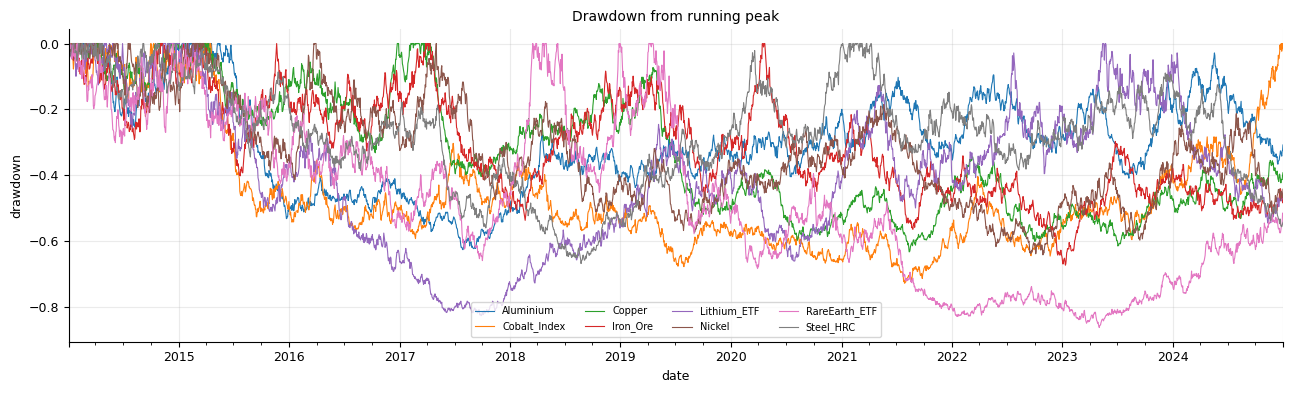

In [7]:
dd = px / px.cummax() - 1
dstat = pd.DataFrame({c: S.drawdown_stats(px[c]) for c in COMS}).T
dstat["days_peak_to_trough"] = (pd.to_datetime(dstat.trough_date) - pd.to_datetime(dstat.peak_date)).dt.days
dstat["days_peak_to_recovery"] = (pd.to_datetime(dstat.recovery_date) - pd.to_datetime(dstat.peak_date)).dt.days
dstat["max_drawdown"] = dstat.max_drawdown.astype(float).round(4); dstat["share_time_under_water"] = dstat.share_time_under_water.astype(float).round(3)
dstat.to_csv(TAB / "A6_drawdowns.csv"); display(dstat)
fig, ax = plt.subplots(figsize=(13, 4)); dd.plot(ax=ax, lw=.8); ax.set_title("Drawdown from running peak"); ax.set_ylabel("drawdown"); ax.legend(ncol=4, fontsize=7); savefig("A6_drawdowns.png")
note("ds2_worst_max_drawdown", f"{dstat.max_drawdown.astype(float).idxmin()} ({dstat.max_drawdown.astype(float).min():.2%})", "deepest peak-to-trough drawdown in DS2")
note("ds2_unrecovered_count", int(dstat.recovery_date.isna().sum()), "commodities whose worst drawdown never recovered within the sample")

## A7 · Tail behaviour, joint extremes and horizon scaling
*Questions: (i) do historical 99% VaR/ES differ from normal-implied ones? (ii) do extremes cluster across commodities more than independence implies? (iii) does variance scale with √horizon (needed to scale 1-day VaR to 10/21 days)?*

,share_|z|>3,normal_expected,q01_hist,q01_normal,VaR99_hist,VaR99_normal,ES99_hist,ES99_normal,VaR_hist/normal,ES_hist/normal
commodity,,,,,,,,,,
Aluminium,0.0024,0.0027,-0.0350,-0.0354,0.0350,0.0354,0.0387,0.0406,0.9894,0.9538
Cobalt_Index,0.0021,0.0027,-0.0472,-0.0464,0.0472,0.0464,0.0558,0.0532,1.0170,1.0479
Copper,0.0017,0.0027,-0.0367,-0.0369,0.0367,0.0369,0.0417,0.0423,0.9959,0.9871
Iron_Ore,0.0038,0.0027,-0.0495,-0.0476,0.0495,0.0476,0.0588,0.0545,1.0403,1.0773
Lithium_ETF,0.0028,0.0027,-0.0589,-0.0581,0.0589,0.0581,0.0698,0.0666,1.0143,1.0479
Nickel,0.0031,0.0027,-0.0497,-0.0501,0.0497,0.0501,0.0570,0.0574,0.9911,0.9920
RareEarth_ETF,0.0031,0.0027,-0.0642,-0.0642,0.0642,0.0642,0.0752,0.0735,1.0007,1.0240
Steel_HRC,0.0021,0.0027,-0.0430,-0.0422,0.0430,0.0422,0.0489,0.0483,1.0184,1.0111


Joint lower-tail days (each commodity's own 1% quantile):


,observed_days,expected_if_independent,ratio
≥2 commodities in own worst 1% same day,7,7.715,0.907
≥3 commodities,0,0.155,0.000


Lo-MacKinlay variance ratios (1.0 = variance scales linearly with horizon):


,VR(5),VR(21),VR(63),z_VR(5),z_VR(21),z_VR(63)
Aluminium,1.065,1.032,1.287,1.582,0.338,1.697
Cobalt_Index,1.051,1.109,1.105,1.252,1.144,0.620
Copper,1.015,1.201,1.572,0.368,2.113,3.380
Iron_Ore,1.028,1.038,1.060,0.686,0.396,0.354
Lithium_ETF,1.008,1.053,1.253,0.183,0.560,1.497
Nickel,1.040,1.024,1.108,0.989,0.249,0.640
RareEarth_ETF,1.041,1.059,1.223,0.995,0.617,1.320
Steel_HRC,1.004,1.092,1.237,0.087,0.968,1.401


Variance ratios after removing calendar-month mean returns (does seasonality explain VR>1?):


,VR(5) after removing month means,VR(21) after removing month means,VR(63) after removing month means
Aluminium,1.029,0.873,0.984
Cobalt_Index,1.018,0.968,0.820
Copper,0.943,0.881,0.798
Iron_Ore,1.001,0.922,0.905
Lithium_ETF,0.976,0.935,1.065
Nickel,0.999,0.868,0.838
RareEarth_ETF,1.020,0.991,1.135
Steel_HRC,0.967,0.914,0.896


21-day VaR: empirical vs √time scaling of 1-day historical VaR


,"VaR99 21d (empirical, overlapping)",VaR99 1d × √21
Aluminium,0.1757,0.1604
Cobalt_Index,0.2140,0.2163
Copper,0.2023,0.1682
Iron_Ore,0.2002,0.2268
Lithium_ETF,0.2548,0.2699
Nickel,0.2207,0.2278
RareEarth_ETF,0.3254,0.2942
Steel_HRC,0.2217,0.1971


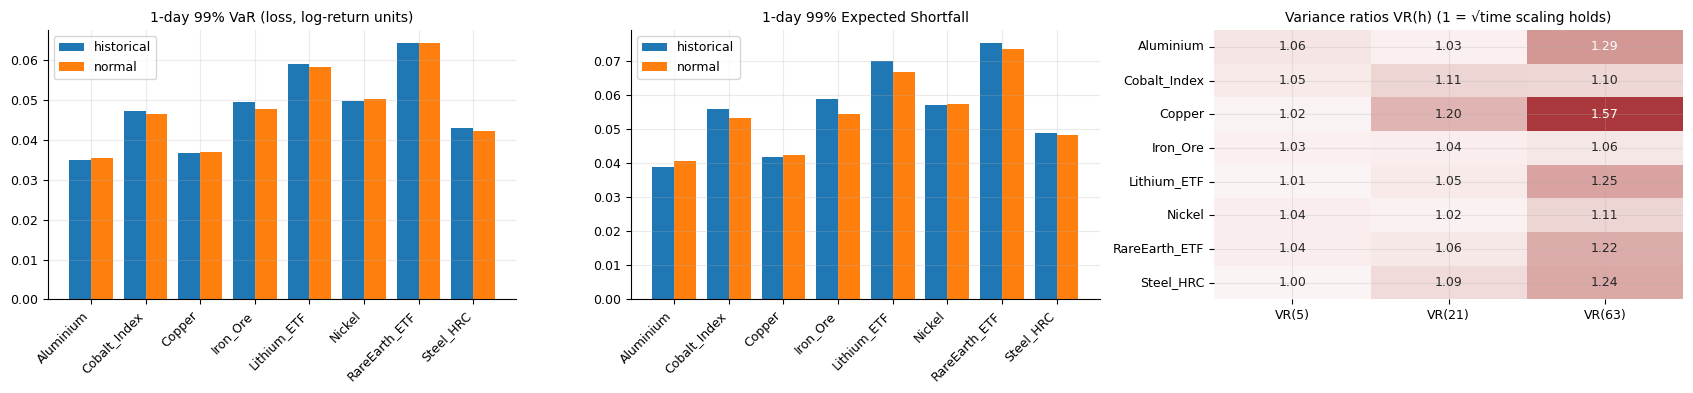

In [8]:
mu, sd = ret.mean(), ret.std(); z = (ret - mu) / sd
zq = sps.norm.ppf(0.01)     # -2.326
tail = pd.DataFrame({"share_|z|>3": (z.abs() > 3).mean(), "normal_expected": 2 * sps.norm.sf(3), "q01_hist": ret.quantile(.01), "q01_normal": mu + zq * sd})
hv = {c: S.hist_var_es(ret[c], .99) for c in COMS}
tail["VaR99_hist"] = [hv[c][0] for c in COMS]; tail["VaR99_normal"] = -(mu + zq * sd).values
tail["ES99_hist"] = [hv[c][1] for c in COMS]; tail["ES99_normal"] = (-mu + sd * sps.norm.pdf(zq) / 0.01).values
tail["VaR_hist/normal"] = tail.VaR99_hist / tail.VaR99_normal; tail["ES_hist/normal"] = tail.ES99_hist / tail.ES99_normal; tail = tail.round(4); tail.to_csv(TAB / "A7_tail_vs_normal.csv"); display(tail)
R = ret.dropna(); low = R.le(R.quantile(.01)); k = low.sum(axis=1); pk = sps.binom(8, .01)
jt = pd.DataFrame({"observed_days": [(k >= 2).sum(), (k >= 3).sum()], "expected_if_independent": [len(R) * pk.sf(1), len(R) * pk.sf(2)]}, index=["≥2 commodities in own worst 1% same day", "≥3 commodities"]); jt["ratio"] = jt.observed_days / jt.expected_if_independent
print("Joint lower-tail days (each commodity's own 1% quantile):"); display(jt.round(3))
vr = pd.DataFrame({h: {c: S.variance_ratio(ret[c], h) for c in COMS} for h in (5, 21, 63)}); T0 = len(R)
zvr = pd.DataFrame({h: (vr[h] - 1) / np.sqrt(2 * (2 * h - 1) * (h - 1) / (3 * h * T0)) for h in vr.columns}); zvr.columns = [f"z_VR({h})" for h in vr.columns]; vr.columns = [f"VR({h})" for h in vr.columns]
vrt = pd.concat([vr, zvr], axis=1).round(3); vrt.to_csv(TAB / "A7_variance_ratios.csv"); print("Lo-MacKinlay variance ratios (1.0 = variance scales linearly with horizon):"); display(vrt)
ret_ds = ret - ret.groupby(ret.index.month).transform("mean")
vr_ds = pd.DataFrame({f"VR({h}) after removing month means": {c: S.variance_ratio(ret_ds[c], h) for c in COMS} for h in (5, 21, 63)})
print("Variance ratios after removing calendar-month mean returns (does seasonality explain VR>1?):"); display(vr_ds.round(3))
note("ds2_VR63_mean_raw", float(vr["VR(63)"].mean()), "mean VR(63) across commodities, raw returns")
note("ds2_VR63_mean_deseasonalised", float(vr_ds.iloc[:, 2].mean()), "mean VR(63) after removing calendar-month mean returns")
h21 = pd.DataFrame({c: [S.hist_var_es(np.log(px[c]).diff(21).dropna(), .99)[0], 21 ** .5 * tail.loc[c, "VaR99_hist"]] for c in COMS}, index=["VaR99 21d (empirical, overlapping)", "VaR99 1d × √21"]).T.round(4); print("21-day VaR: empirical vs √time scaling of 1-day historical VaR"); display(h21)
fig, ax = plt.subplots(1, 3, figsize=(17, 4)); x = np.arange(8)
ax[0].bar(x - .2, tail.VaR99_hist, .4, label="historical"); ax[0].bar(x + .2, tail.VaR99_normal, .4, label="normal"); ax[0].set_xticks(x); ax[0].set_xticklabels(COMS, rotation=45, ha="right"); ax[0].set_title("1-day 99% VaR (loss, log-return units)"); ax[0].legend()
ax[1].bar(x - .2, tail.ES99_hist, .4, label="historical"); ax[1].bar(x + .2, tail.ES99_normal, .4, label="normal"); ax[1].set_xticks(x); ax[1].set_xticklabels(COMS, rotation=45, ha="right"); ax[1].set_title("1-day 99% Expected Shortfall"); ax[1].legend()
sns.heatmap(vr, annot=True, fmt=".2f", cmap="vlag", center=1, ax=ax[2], cbar=False); ax[2].set_title("Variance ratios VR(h) (1 = √time scaling holds)")
savefig("A7_tails_vr.png")
note("ds2_VaR_hist_over_normal_median", float(tail["VaR_hist/normal"].median()), "median ratio of historical to normal 99% VaR (1 = normal adequate)")
note("ds2_ES_hist_over_normal_median", float(tail["ES_hist/normal"].median()), "median ratio of historical to normal 99% ES")
note("ds2_joint_tail_ratio_ge2", float(jt.iloc[0, 2]), "observed/expected days with >=2 commodities simultaneously in own worst 1% (1 = independence)")
note("ds2_VR21_range", f"{vr['VR(21)'].min():.2f}-{vr['VR(21)'].max():.2f}", "range of 21-day variance ratios across commodities")
note("ds2_VR21_sig_count", int((zvr["z_VR(21)"].abs() > 1.96).sum()), "commodities where VR(21) differs from 1 at 5% (iid z-test)")

## A8 · Cross-commodity dependence and diversification
*Question: do the commodities co-move? If correlations are ≈ 0, portfolio diversification benefit is large — but this must be compared with what real commodity markets show before it is trusted for risk.*

daily return correlation: mean=+0.008, max=+0.038, min=-0.019 | pairs significant (BH q<0.05): 0 of 28
correlation-matrix eigenvalues: [1.06, 1.03, 1.03, 1.01, 1.0, 0.98, 0.95, 0.93] | Marchenko-Pastur noise edge = 1.11 | largest eigenvalue/ N = 13.30% | effective number of independent assets = 7.99 of 8


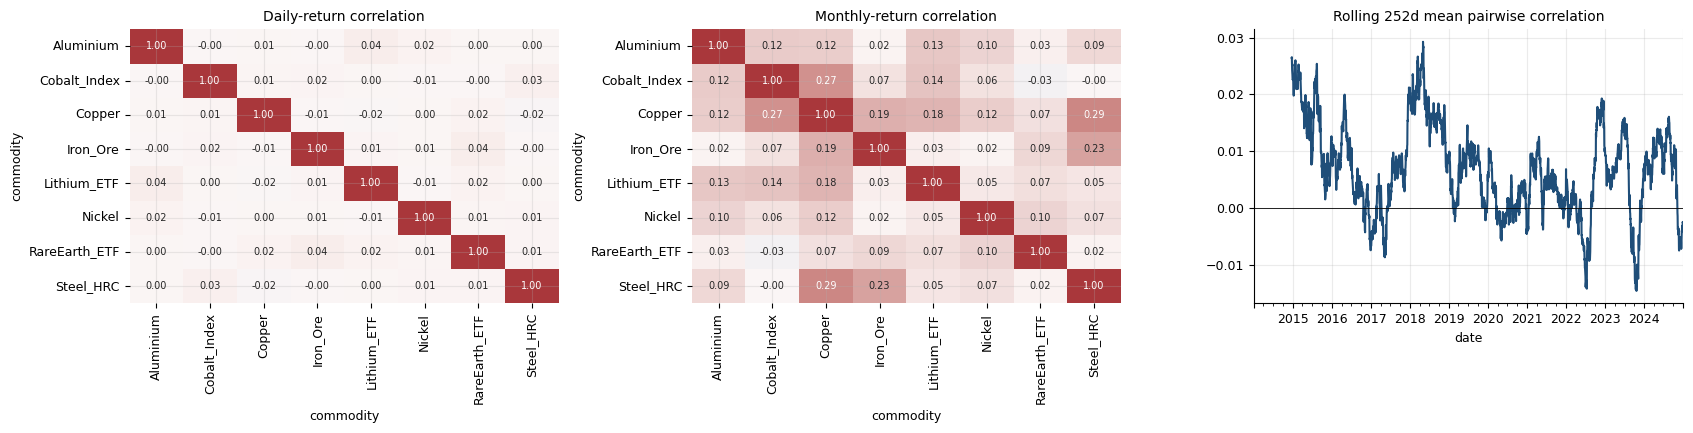

In [9]:
corr_d = ret.corr(); lm = np.log(px.resample("ME").last()).diff(); corr_m = lm.corr()
pairs = list(combinations(COMS, 2)); pp = [sps.pearsonr(R[a], R[b]) for a, b in pairs]; qv = S.bh_fdr([p[1] for p in pp])
offd = np.array([p[0] for p in pp]); print(f"daily return correlation: mean={offd.mean():+.3f}, max={offd.max():+.3f}, min={offd.min():+.3f} | pairs significant (BH q<0.05): {int((qv<.05).sum())} of {len(pairs)}")
roll = pd.concat([ret[a].rolling(252).corr(ret[b]) for a, b in pairs], axis=1).mean(axis=1)
ev = np.linalg.eigvalsh(corr_d.values)[::-1]; mp = S.marchenko_pastur_upper(len(R), 8); neff = ev.sum() ** 2 / (ev ** 2).sum()
print(f"correlation-matrix eigenvalues: {np.round(ev, 2).tolist()} | Marchenko-Pastur noise edge = {mp:.2f} | largest eigenvalue/ N = {ev[0] / 8:.2%} | effective number of independent assets = {neff:.2f} of 8")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.heatmap(corr_d, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.5, vmax=.5, ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Daily-return correlation")
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.5, vmax=.5, ax=ax[1], cbar=False, annot_kws={"size": 7}); ax[1].set_title("Monthly-return correlation")
roll.plot(ax=ax[2], color="#1f4e79"); ax[2].axhline(0, color="k", lw=.6); ax[2].set_title("Rolling 252d mean pairwise correlation")
savefig("A8_dependence.png")
note("ds2_mean_pairwise_corr", float(offd.mean()), "mean pairwise daily-return correlation across the 8 commodities")
note("ds2_max_abs_pairwise_corr", float(np.abs(offd).max()), "largest |pairwise correlation|")
note("ds2_sig_pairs_bh", int((qv < .05).sum()), "pairs of commodities with significant correlation (BH q<0.05), of 28")
note("ds2_effective_independent_assets", float(neff), "effective number of independent assets from the correlation spectrum (8 = fully independent)")
note("ds2_largest_eigenvalue", float(ev[0]), "largest eigenvalue of the daily correlation matrix (1.0 = no common factor)")

## A9 · Term spread, volume and intraday range
*Questions: does the `term_spread` carry information about next-period returns or volatility? Is volume related to absolute returns? Is the OHLC range consistent with close-to-close volatility (a data-integrity check on the intraday fields)?*

term_spread summary:


,mean,std,share_positive,min,max
commodity,,,,,
Aluminium,-1.9955,11.5840,0.4298,-42.1169,52.4090
Cobalt_Index,-2.0225,5.0439,0.3371,-20.6142,15.7439
Copper,-1.9346,5.0115,0.3472,-22.1352,15.2727
Iron_Ore,-2.0960,4.9148,0.3374,-18.7650,14.0117
Lithium_ETF,-1.8824,5.1430,0.3604,-18.6240,14.6772
Nickel,0.3964,161.7629,0.4866,-730.6413,652.1251
RareEarth_ETF,-2.0697,5.0073,0.3350,-19.5109,13.0097
Steel_HRC,-1.9817,6.1711,0.3733,-25.5715,20.7193


term_spread vs forward return (non-overlapping samples); significant after BH: 0 of 24


horizon,1,5,21
commodity,,,
Aluminium,0.032,0.103,0.003
Cobalt_Index,-0.007,-0.008,0.075
Copper,-0.024,0.000,-0.040
Iron_Ore,0.008,0.007,-0.002
Lithium_ETF,0.004,-0.061,0.014
Nickel,0.024,0.031,0.028
RareEarth_ETF,0.016,-0.014,0.076
Steel_HRC,-0.010,0.025,0.028


term_spread scale differs across commodities: std ranges 4.9-161.8 (Nickel=162, median=5.1) -> units are not comparable; use within-commodity ranks/z-scores only
Spearman(volume, |daily return|) by commodity: {'Aluminium': 0.016, 'Cobalt_Index': 0.016, 'Copper': -0.04, 'Iron_Ore': -0.041, 'Lithium_ETF': 0.028, 'Nickel': -0.03, 'RareEarth_ETF': 0.007, 'Steel_HRC': -0.03}
Parkinson (high-low) annualised vol / close-to-close vol: {'Aluminium': 0.514, 'Cobalt_Index': 0.39, 'Copper': 0.495, 'Iron_Ore': 0.383, 'Lithium_ETF': 0.313, 'Nickel': 0.362, 'RareEarth_ETF': 0.283, 'Steel_HRC': 0.433} (≈1 for a consistent OHLC process; >1 means intraday range exceeds what close-to-close returns imply)


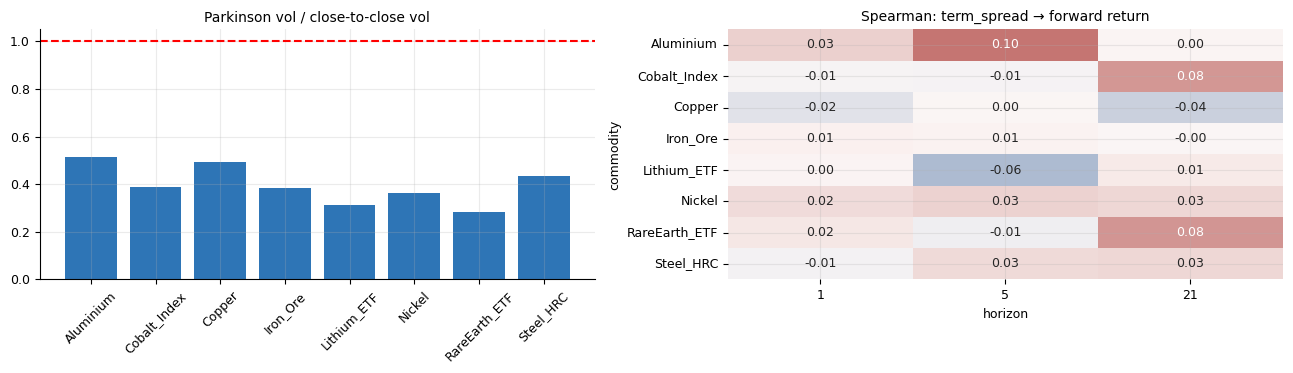

In [10]:
ts = d2.pivot(index="date", columns="commodity", values="term_spread")[COMS]; vol_ = d2.pivot(index="date", columns="commodity", values="volume")[COMS]
hi, lo = d2.pivot(index="date", columns="commodity", values="high")[COMS], d2.pivot(index="date", columns="commodity", values="low")[COMS]
print("term_spread summary:"); display(pd.DataFrame({"mean": ts.mean(), "std": ts.std(), "share_positive": (ts > 0).mean(), "min": ts.min(), "max": ts.max()}).round(4))
def fwd(h): return np.log(px.shift(-h) / px)
rows = []
for c in COMS:
    for h in (1, 5, 21):
        idx = np.arange(0, len(px) - h, h); x, y = ts[c].iloc[idx], fwd(h)[c].iloc[idx]; r, p, n = S.spearman_with_p(x, y); rows.append({"commodity": c, "horizon": h, "rho": r, "p": p, "n": n})
tsr = pd.DataFrame(rows); tsr["q"] = S.bh_fdr(tsr.p); print("term_spread vs forward return (non-overlapping samples); significant after BH:", int((tsr.q < .05).sum()), "of", len(tsr)); display(tsr.pivot(index="commodity", columns="horizon", values="rho").round(3))
tsd = ts.std(); print(f"term_spread scale differs across commodities: std ranges {tsd.min():.1f}-{tsd.max():.1f} (Nickel={tsd['Nickel']:.0f}, median={tsd.median():.1f}) -> units are not comparable; use within-commodity ranks/z-scores only")
note("ds2_term_spread_std_ratio_max_over_median", float(tsd.max() / tsd.median()), "term_spread std: max commodity / median commodity (unit inconsistency)")
vs = pd.Series({c: S.spearman_with_p(vol_[c], ret[c].abs())[0] for c in COMS}); print("Spearman(volume, |daily return|) by commodity:", vs.round(3).to_dict())
park = np.sqrt(((np.log(hi / lo)) ** 2 / (4 * np.log(2))).mean() * ANN); cc = ret.std() * np.sqrt(ANN); pr = (park / cc).round(3)
print("Parkinson (high-low) annualised vol / close-to-close vol:", pr.to_dict(), "(≈1 for a consistent OHLC process; >1 means intraday range exceeds what close-to-close returns imply)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); ax[0].bar(pr.index, pr.values, color="#2e75b6"); ax[0].axhline(1, color="r", ls="--"); ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Parkinson vol / close-to-close vol")
sns.heatmap(tsr.pivot(index="commodity", columns="horizon", values="rho"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.15, vmax=.15, ax=ax[1], cbar=False); ax[1].set_title("Spearman: term_spread → forward return")
savefig("A9_term_volume_range.png")
note("ds2_term_spread_sig_count", int((tsr.q < .05).sum()), "term_spread->forward return tests significant after BH (of 24)")
note("ds2_term_spread_max_abs_rho", float(tsr.rho.abs().max()), "largest |Spearman| between term_spread and forward return")
note("ds2_volume_abs_ret_rho_mean", float(vs.mean()), "mean Spearman(volume, |return|)")
note("ds2_parkinson_ratio_median", float(pr.median()), "median Parkinson/close-to-close volatility ratio")

# PART B — DS4 cross-domain features and their link to DS2
The join `(date, commodity)` is exact 1:1 (audit). All DS4 trends are backward-looking (rule DS4-06), so DS4 values at date *t* are legitimately known at *t*.

In [11]:
m = d2[["date", "commodity", "close", "daily_return", "volatility_21d_ann", "term_spread"]].merge(d4, on=["date", "commodity"], how="inner", validate="one_to_one")
m = m.sort_values(["commodity", "date"]).reset_index(drop=True); g = m.groupby("commodity")
for h in (1, 5, 21, 63): m[f"fwd_ret_{h}"] = g.close.transform(lambda s: np.log(s.shift(-h) / s))
m["fwd_vol_21"] = g.daily_return.transform(lambda s: s[::-1].rolling(21).std()[::-1].shift(-1)) * np.sqrt(ANN)   # vol of returns t+1..t+21 only
print("merged rows:", len(m), "(DS2 rows:", len(d2), ") | forward window never includes day t's own return:", bool(m.groupby("commodity").fwd_vol_21.apply(lambda s: s.iloc[-21:].isna().all()).all()))
FEATS = ["mqi", "mqi_5d_trend", "mqi_21d_trend", "mqi_63d_trend", "supply_disruption_prob", "substitution_elasticity", "green_premium_per_kg", "carbon_intensity_virgin", "carbon_intensity_recycled", "herfindahl_index"]

merged rows: 22952 (DS2 rows: 22952 ) | forward window never includes day t's own return: True


## B1 · What kind of variables are the DS4 features?
*Question: are they genuinely time-varying per commodity, or mostly commodity-level constants? (Between-commodity share of variance, η².)*

,between_commodity_share(eta2),within_commodity_sd_mean,overall_sd,within_cv_mean
mqi,0.8148,3.3560,7.8349,0.0450
mqi_5d_trend,0.0000,1.0920,1.0921,494.0951
mqi_21d_trend,0.0001,2.1216,2.1232,110.9647
mqi_63d_trend,0.0004,3.3096,3.3160,178.1247
supply_disruption_prob,0.9759,0.0393,0.2542,0.1944
substitution_elasticity,0.9873,0.0200,0.1778,0.0786
green_premium_per_kg,0.9985,0.0340,1.3680,0.0300
carbon_intensity_virgin,0.9989,0.2227,8.3956,0.0199
carbon_intensity_recycled,0.9985,0.0985,4.1538,0.0304
herfindahl_index,0.9994,0.0050,0.2011,0.0275


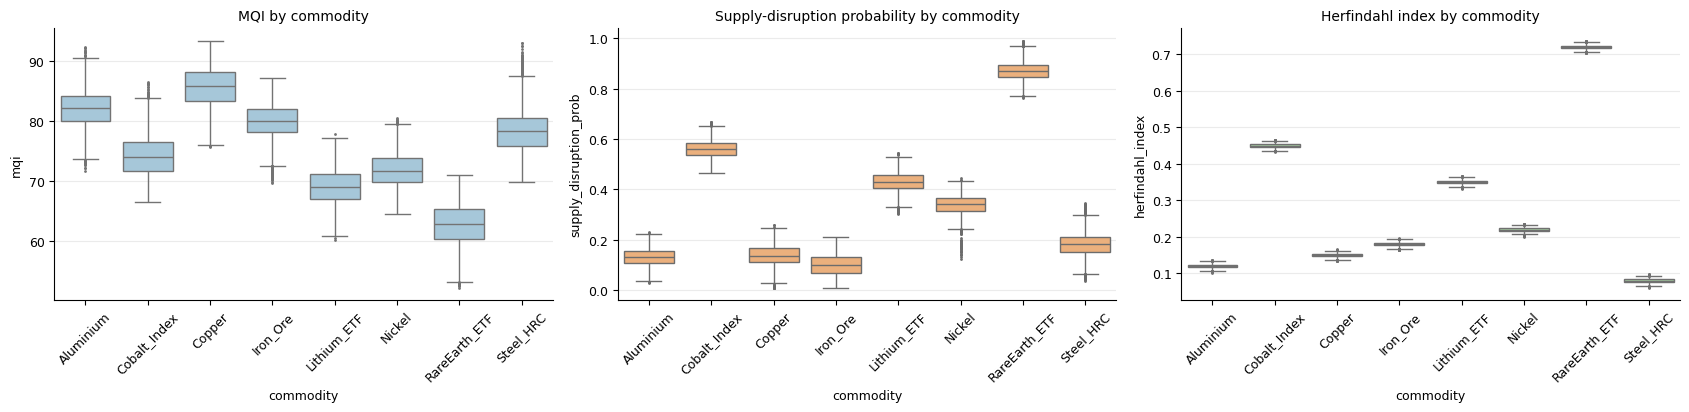

In [12]:
vd = pd.DataFrame({f: {"between_commodity_share(eta2)": S.eta_squared(m[f], m.commodity), "within_commodity_sd_mean": m.groupby("commodity")[f].std().mean(), "overall_sd": m[f].std(),
                       "within_cv_mean": (m.groupby("commodity")[f].std() / m.groupby("commodity")[f].mean().abs()).mean()} for f in FEATS}).T.round(4)
vd.to_csv(TAB / "B1_ds4_variance_decomposition.csv"); display(vd)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.boxplot(data=m, x="commodity", y="mqi", ax=ax[0], color="#9ecae1", fliersize=1); ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("MQI by commodity")
sns.boxplot(data=m, x="commodity", y="supply_disruption_prob", ax=ax[1], color="#fdae6b", fliersize=1); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Supply-disruption probability by commodity")
sns.boxplot(data=m, x="commodity", y="herfindahl_index", ax=ax[2], color="#a1d99b", fliersize=1); ax[2].tick_params(axis="x", rotation=45); ax[2].set_title("Herfindahl index by commodity")
savefig("B1_ds4_by_commodity.png")
note("ds4_mqi_between_share", float(vd.loc["mqi", "between_commodity_share(eta2)"]), "share of MQI variance that is between commodities")
note("ds4_supply_between_share", float(vd.loc["supply_disruption_prob", "between_commodity_share(eta2)"]), "share of supply_disruption_prob variance between commodities")
note("ds4_hhi_between_share", float(vd.loc["herfindahl_index", "between_commodity_share(eta2)"]), "share of Herfindahl variance between commodities")

## B2 · Time-series structure of MQI and supply-disruption probability
*Question: are they persistent/trending/mean-reverting, and do they move with market stress (volatility) contemporaneously?*

,AR1,autocorr_lag21,ADF_p,slope_per_year,slope_p,half_life_days
commodity,,,,,,
Aluminium,0.9887,0.7707,0.0007,-0.1277,0.0000,61.0556
Cobalt_Index,0.9895,0.8287,0.0027,-0.0992,0.0000,65.9506
Copper,0.9891,0.7975,0.0016,-0.0476,0.0134,63.3948
Iron_Ore,0.9865,0.7578,0.0006,-0.2351,0.0000,50.8683
Lithium_ETF,0.9860,0.7845,0.0010,-0.1069,0.0000,49.1402
Nickel,0.9853,0.7513,0.0001,-0.2831,0.0000,46.7752
RareEarth_ETF,0.9909,0.8374,0.0095,-0.1853,0.0000,76.1804
Steel_HRC,0.9919,0.8443,0.0085,0.2609,0.0000,85.6745


,AR1,autocorr_lag21,ADF_p,slope_per_year,slope_p,half_life_days
commodity,,,,,,
Aluminium,0.9738,0.5498,0.0000,-0.0010,0.000,26.1412
Cobalt_Index,0.9733,0.5541,0.0000,0.0022,0.000,25.6231
Copper,0.9800,0.7119,0.0000,0.0015,0.000,34.2769
Iron_Ore,0.9822,0.6821,0.0000,0.0003,0.295,38.6521
Lithium_ETF,0.9760,0.5539,0.0000,0.0009,0.000,28.5670
Nickel,0.9786,0.6258,0.0000,-0.0009,0.000,32.0526
RareEarth_ETF,0.9775,0.5885,0.0000,0.0013,0.000,30.5085
Steel_HRC,0.9852,0.7030,0.0001,-0.0023,0.000,46.4707


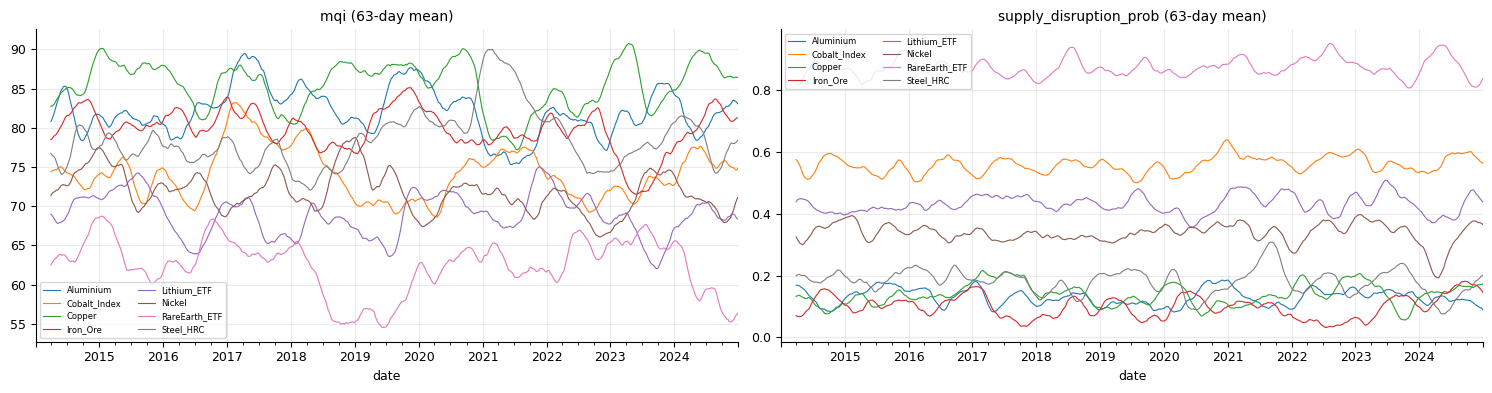

Within-commodity Spearman with trailing 21d volatility (same day):


,rho_mqi_vol21,rho_supply_vol21
commodity,,
Aluminium,-0.060,-0.005
Cobalt_Index,-0.005,0.030
Copper,-0.116,0.099
Iron_Ore,0.128,-0.052
Lithium_ETF,-0.152,0.074
Nickel,0.116,0.171
RareEarth_ETF,0.029,0.030
Steel_HRC,-0.094,-0.141


In [13]:
rows = {}
for c in COMS:
    for f in ("mqi", "supply_disruption_prob"):
        x = m.loc[m.commodity == c, f].values; ar1 = pd.Series(x).autocorr(1); tt_ = np.arange(len(x)) / ANN; sl = sps.linregress(tt_, x)
        rows[(c, f)] = {"AR1": ar1, "autocorr_lag21": pd.Series(x).autocorr(21), "ADF_p": adfuller(x, regression="c", autolag="AIC")[1], "slope_per_year": sl.slope, "slope_p": sl.pvalue, "half_life_days": (np.log(.5) / np.log(ar1) if 0 < ar1 < 1 else np.nan)}
ts4 = pd.DataFrame(rows).T.round(4); ts4.index.names = ["commodity", "feature"]; ts4.to_csv(TAB / "B2_ds4_time_series.csv"); display(ts4.xs("mqi", level=1)); display(ts4.xs("supply_disruption_prob", level=1))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for f, a in zip(("mqi", "supply_disruption_prob"), ax):
    m.pivot(index="date", columns="commodity", values=f).rolling(63).mean().plot(ax=a, lw=.8); a.set_title(f"{f} (63-day mean)"); a.legend(ncol=2, fontsize=6)
savefig("B2_ds4_time_series.png")
wv = m.groupby("commodity").apply(lambda d: pd.Series({"rho_mqi_vol21": S.spearman_with_p(d.mqi, d.volatility_21d_ann)[0], "rho_supply_vol21": S.spearman_with_p(d.supply_disruption_prob, d.volatility_21d_ann)[0]})).round(3)
print("Within-commodity Spearman with trailing 21d volatility (same day):"); display(wv)
note("ds4_mqi_median_AR1", float(ts4.xs("mqi", level=1).AR1.median()), "median lag-1 autocorrelation of MQI")
note("ds4_supply_median_AR1", float(ts4.xs("supply_disruption_prob", level=1).AR1.median()), "median lag-1 autocorrelation of supply_disruption_prob")
note("ds4_mqi_ADF_nonstationary", int((ts4.xs("mqi", level=1).ADF_p > .05).sum()), "commodities where MQI has a unit root (ADF p>0.05)")

## B3 · Do DS4 features predict returns or volatility?
Design (to avoid common pitfalls): features at date *t*; outcomes strictly after *t* (`fwd_ret_h` = ln(P_{t+h}/P_t), `fwd_vol_21` = realised vol of returns t+1…t+21);
rank correlation **within each commodity** (so between-commodity level differences cannot masquerade as a relationship), on **non-overlapping** samples (every *h*-th day),
combined across commodities by Stouffer's method; BH across all feature × outcome tests. Same-day and trailing-volatility rows are *contemporaneous associations*, not forecasts.

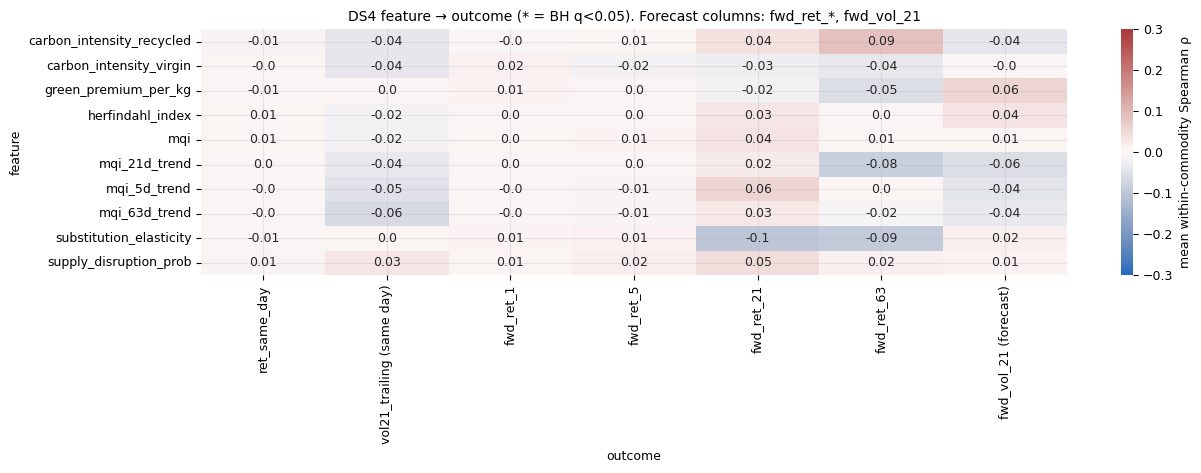

FORECAST tests (feature→future return): 40 tests, BH-significant: 0, max |ρ| = 0.099
FORECAST tests (feature→future volatility): 10 tests, BH-significant: 0, max |ρ| = 0.058
Strongest results overall:


,feature,outcome,mean_rho,p,n_per_commodity,q
39,substitution_elasticity,fwd_ret_21,-0.0986,0.0012,136,0.0834
40,substitution_elasticity,fwd_ret_63,-0.0897,0.0959,45,0.6460
61,carbon_intensity_recycled,fwd_ret_63,0.0884,0.1251,45,0.6460
19,mqi_21d_trend,fwd_ret_63,-0.0843,0.1168,44,0.6460
22,mqi_63d_trend,vol21_trailing (same day),-0.0611,0.0464,134,0.6460
48,green_premium_per_kg,fwd_vol_21 (forecast),0.0577,0.0775,136,0.6460
11,mqi_5d_trend,fwd_ret_21,0.0567,0.0645,135,0.6460
20,mqi_21d_trend,fwd_vol_21 (forecast),-0.0550,0.0725,135,0.6460
47,green_premium_per_kg,fwd_ret_63,-0.0546,0.3376,45,0.7267
8,mqi_5d_trend,vol21_trailing (same day),-0.0490,0.1085,136,0.6460


In [14]:
TARG = {"ret_same_day": ("daily_return", 1), "vol21_trailing (same day)": ("volatility_21d_ann", 21), "fwd_ret_1": ("fwd_ret_1", 1), "fwd_ret_5": ("fwd_ret_5", 5),
        "fwd_ret_21": ("fwd_ret_21", 21), "fwd_ret_63": ("fwd_ret_63", 63), "fwd_vol_21 (forecast)": ("fwd_vol_21", 21)}
rows = []
for f in FEATS:
    for tname, (tcol, step) in TARG.items():
        rs, ns = [], []
        for c in COMS:
            d = m[m.commodity == c].iloc[::step]; x, y = d[f], d[tcol]
            if x.nunique() < 3: continue
            r, p, n = S.spearman_with_p(x, y)
            if np.isfinite(r): rs.append(r); ns.append(n)
        if not rs: rows.append({"feature": f, "outcome": tname, "mean_rho": np.nan, "p": np.nan}); continue
        Z = np.sum([np.arctanh(r) * np.sqrt(n - 3) for r, n in zip(rs, ns)]) / np.sqrt(len(rs))
        rows.append({"feature": f, "outcome": tname, "mean_rho": float(np.mean(rs)), "p": float(2 * sps.norm.sf(abs(Z))), "n_per_commodity": int(np.mean(ns))})
pr_ = pd.DataFrame(rows); pr_["q"] = S.bh_fdr(pr_.p); pr_.to_csv(TAB / "B3_ds4_predictive_tests.csv", index=False)
H = pr_.pivot(index="feature", columns="outcome", values="mean_rho")[list(TARG)]; Q = pr_.pivot(index="feature", columns="outcome", values="q")[list(TARG)]
ann = H.round(2).astype(str) + np.where(Q < .05, "*", ""); ann = ann.where(H.notna(), "n/a")
fig, ax = plt.subplots(figsize=(13, 4.8)); sns.heatmap(H, annot=ann, fmt="", cmap="vlag", center=0, vmin=-.3, vmax=.3, ax=ax, cbar_kws={"label": "mean within-commodity Spearman ρ"}); ax.set_title("DS4 feature → outcome (* = BH q<0.05). Forecast columns: fwd_ret_*, fwd_vol_21")
savefig("B3_ds4_predictive.png")
fc = pr_[pr_.outcome.isin(["fwd_ret_1", "fwd_ret_5", "fwd_ret_21", "fwd_ret_63"])]; fv = pr_[pr_.outcome == "fwd_vol_21 (forecast)"]
print(f"FORECAST tests (feature→future return): {len(fc)} tests, BH-significant: {int((fc.q<.05).sum())}, max |ρ| = {fc.mean_rho.abs().max():.3f}")
print(f"FORECAST tests (feature→future volatility): {len(fv)} tests, BH-significant: {int((fv.q<.05).sum())}, max |ρ| = {fv.mean_rho.abs().max():.3f}")
print("Strongest results overall:"); display(pr_.reindex(pr_.mean_rho.abs().sort_values(ascending=False).index).head(10).round(4))
note("ds4_forecast_return_tests_sig", f"{int((fc.q<.05).sum())} of {len(fc)}", "DS4 feature -> future return tests significant after BH")
note("ds4_forecast_return_max_abs_rho", float(fc.mean_rho.abs().max()), "largest |within-commodity rho| between a DS4 feature and a future return")
note("ds4_forecast_vol_tests_sig", f"{int((fv.q<.05).sum())} of {len(fv)}", "DS4 feature -> future volatility tests significant after BH")
note("ds4_forecast_vol_max_abs_rho", float(fv.mean_rho.abs().max()), "largest |rho| between a DS4 feature and future 21d volatility")

## B4 · Stress-state event study
*Question: when supply-disruption probability is in a commodity's top decile (or MQI / MQI trend in its bottom decile), do subsequent 21-day volatility or return differ?
Deciles are computed **within commodity**; outcomes are z-scored within commodity; samples are non-overlapping (every 21st day).*

,condition,outcome,n_condition,mean_z_condition,mean_z_rest,difference,welch_p,q
0,supply_disruption_prob: top decile,fwd_vol_21_z,112,0.1258,-0.0144,0.1402,0.1705,0.3322
1,supply_disruption_prob: top decile,fwd_ret_21_z,112,-0.0318,0.0036,-0.0354,0.7449,0.7449
2,MQI: bottom decile,fwd_vol_21_z,112,0.1465,-0.0168,0.1633,0.1249,0.3322
3,MQI: bottom decile,fwd_ret_21_z,112,-0.1293,0.0148,-0.1441,0.1546,0.3322
4,MQI 21d trend: bottom decile,fwd_vol_21_z,112,0.1229,-0.0141,0.1370,0.2215,0.3322
5,MQI 21d trend: bottom decile,fwd_ret_21_z,112,-0.0742,0.0085,-0.0828,0.4047,0.4857


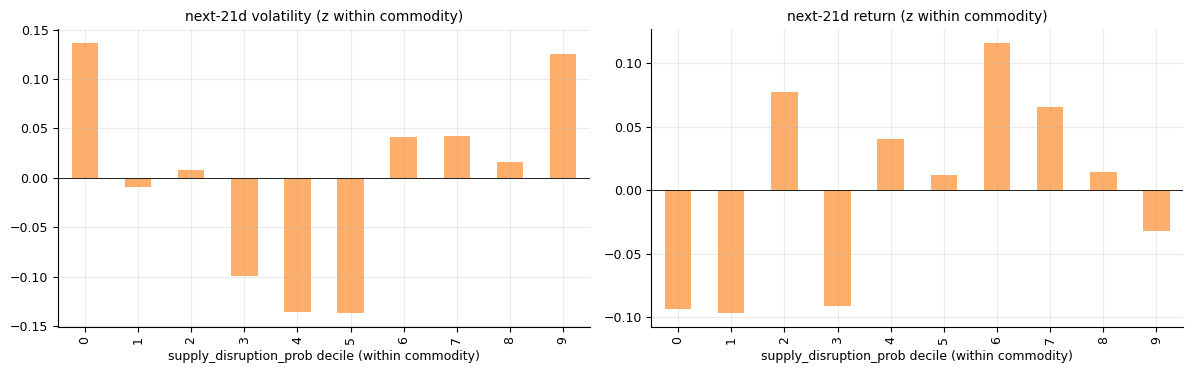

In [15]:
s21 = m.groupby("commodity", group_keys=False).apply(lambda d: d.iloc[::21]).copy()
for o in ("fwd_vol_21", "fwd_ret_21"): s21[o + "_z"] = s21.groupby("commodity")[o].transform(lambda s: (s - s.mean()) / s.std())
s21["supply_dec"] = s21.groupby("commodity").supply_disruption_prob.transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False))
s21["mqi_dec"] = s21.groupby("commodity").mqi.transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False))
s21["mqitr_dec"] = s21.groupby("commodity").mqi_21d_trend.transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False))
cond = {"supply_disruption_prob: top decile": s21.supply_dec == 9, "MQI: bottom decile": s21.mqi_dec == 0, "MQI 21d trend: bottom decile": s21.mqitr_dec == 0}
res = []
for cn, mask in cond.items():
    for o in ("fwd_vol_21_z", "fwd_ret_21_z"):
        a, b = s21.loc[mask, o].dropna(), s21.loc[~mask, o].dropna(); t = sps.ttest_ind(a, b, equal_var=False)
        res.append({"condition": cn, "outcome": o, "n_condition": len(a), "mean_z_condition": a.mean(), "mean_z_rest": b.mean(), "difference": a.mean() - b.mean(), "welch_p": t.pvalue})
ev_ = pd.DataFrame(res); ev_["q"] = S.bh_fdr(ev_.welch_p); ev_ = ev_.round(4); ev_.to_csv(TAB / "B4_event_study.csv", index=False); display(ev_)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, o, t in zip(ax, ("fwd_vol_21_z", "fwd_ret_21_z"), ("next-21d volatility (z within commodity)", "next-21d return (z within commodity)")):
    s21.groupby("supply_dec")[o].mean().plot.bar(ax=a, color="#fdae6b"); a.axhline(0, color="k", lw=.6); a.set_xlabel("supply_disruption_prob decile (within commodity)"); a.set_title(t)
savefig("B4_decile_event_study.png")
note("ds4_event_study_sig", f"{int((ev_.q<.05).sum())} of {len(ev_)}", "stress-state event-study contrasts significant after BH")
note("ds4_event_study_max_abs_diff_z", float(ev_.difference.abs().max()), "largest |difference| in z-units between stress state and rest")

# PART C — DS5 element prices and their link to DS1 and DS2
The audit found DS5's supplied `monthly_return` irreconcilable with its prices, so all returns below are derived from `price_usd_per_kg`.
## C1 · Price levels, resolution and dynamics
*Question: how large and how dynamic are element costs, and is price resolution adequate for the cheap elements?*

,mean_price,max/min,CAGR,ann_vol_price_derived,ann_vol_supplied_return,share_months_unchanged,supplied/derived_vol
element,,,,,,,
Au,53876.2004,1.1505,0.0040,0.0268,0.5073,0.0,18.9227
Pt,28686.7405,1.1433,0.0006,0.0279,0.6471,0.0,23.1544
Sc,4010.1286,1.1123,-0.0048,0.0346,0.7947,0.0,22.9985
Re,2870.2473,1.0999,-0.0061,0.0297,0.5623,0.0,18.9426
Ge,939.6908,1.1828,-0.0087,0.0367,0.6399,0.0,17.4178
Hf,923.5504,1.0909,0.0045,0.0310,0.5885,0.0,18.9672
Ag,592.0778,1.1996,-0.0012,0.0322,0.5534,0.0,17.2100
Dy,331.3920,1.2570,0.0082,0.0550,1.0142,0.0,18.4346
Ga,311.2884,1.1351,0.0061,0.0344,0.7081,0.0,20.6032


,mean_price,max/min,CAGR,ann_vol_price_derived,ann_vol_supplied_return,share_months_unchanged,supplied/derived_vol
element,,,,,,,
Al,2.1855,1.0861,0.0033,0.0221,0.4767,0.3053,21.5855
Pb,2.1260,1.0945,0.0017,0.0229,0.4988,0.2290,21.7349
Mn,1.9986,1.2056,0.0000,0.0365,0.6037,0.1832,16.5195
C,0.4829,1.1087,0.0018,0.0430,0.6672,0.6412,15.5034
N,0.2951,1.1071,-0.0063,0.0562,0.5589,0.7710,9.9409
Fe,0.0965,1.1111,-0.0096,0.0958,0.5990,0.9313,6.2543


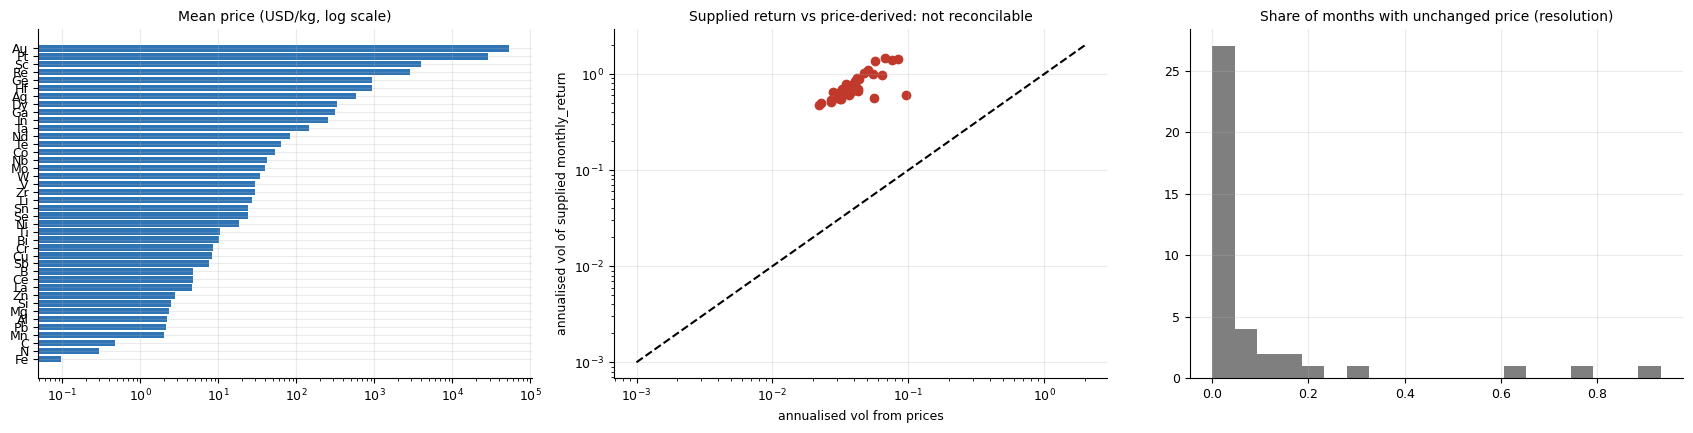

In [16]:
p5 = d5.pivot(index="date", columns="element", values="price_usd_per_kg"); r5 = p5.pct_change().iloc[1:]; sup5 = d5.pivot(index="date", columns="element", values="monthly_return").iloc[1:]
yrs5 = (p5.index[-1] - p5.index[0]).days / 365.25
e = pd.DataFrame({"mean_price": p5.mean(), "max/min": p5.max() / p5.min(), "CAGR": (p5.iloc[-1] / p5.iloc[0]) ** (1 / yrs5) - 1, "ann_vol_price_derived": r5.std() * np.sqrt(12),
                  "ann_vol_supplied_return": sup5.std() * np.sqrt(12), "share_months_unchanged": (p5.diff() == 0).iloc[1:].mean()}).sort_values("mean_price", ascending=False)
e["supplied/derived_vol"] = e.ann_vol_supplied_return / e.ann_vol_price_derived; e.round(4).to_csv(TAB / "C1_element_price_summary.csv"); display(e.round(4).head(12)); display(e.round(4).tail(6))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].barh(e.index[::-1], e.mean_price[::-1], color="#2e75b6"); ax[0].set_xscale("log"); ax[0].set_title("Mean price (USD/kg, log scale)")
ax[1].scatter(e.ann_vol_price_derived, e.ann_vol_supplied_return, c="#c0392b"); lim = [1e-3, 2]; ax[1].plot(lim, lim, "k--"); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("annualised vol from prices"); ax[1].set_ylabel("annualised vol of supplied monthly_return"); ax[1].set_title("Supplied return vs price-derived: not reconcilable")
ax[2].hist(e.share_months_unchanged, bins=20, color="#7f7f7f"); ax[2].set_title("Share of months with unchanged price (resolution)")
savefig("C1_element_prices.png")
note("ds5_median_price_derived_ann_vol", float(e.ann_vol_price_derived.median()), "median annualised volatility of element prices (price-derived)")
note("ds5_median_supplied_over_derived_vol", float(e["supplied/derived_vol"].median()), "supplied monthly_return vol / price-derived vol (1 = consistent)")
note("ds5_max_price_range_ratio", float(e["max/min"].max()), "largest max/min price ratio over 11 years across 40 elements")
note("ds5_elements_with_unchanged_gt50pct", int((e.share_months_unchanged > .5).sum()), "elements whose price is unchanged in >50% of months (rounding)")

## C2 · Co-movement of element prices
*Question: do element costs share a common factor (as real commodity prices do)? (Eigenvalue spectrum vs Marchenko–Pastur noise edge; elements with zero variance excluded.)*

40 elements with non-zero price variance | mean pairwise corr = -0.001, max |corr| = 0.246
largest eigenvalue = 2.10 vs Marchenko-Pastur noise edge 2.41; eigenvalues above the edge: 0 of 40


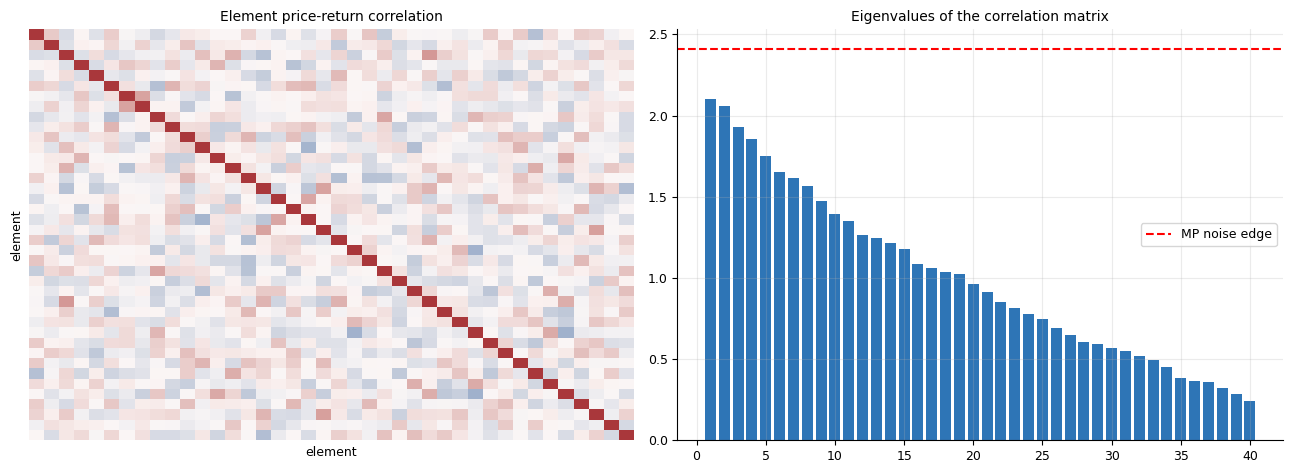

In [17]:
r5v = r5.loc[:, r5.std() > 0]; c5 = r5v.corr(); n_el = c5.shape[0]; ev5 = np.linalg.eigvalsh(c5.values)[::-1]; mp5 = S.marchenko_pastur_upper(len(r5v), n_el)
offd5 = c5.values[np.triu_indices(n_el, 1)]
print(f"{n_el} elements with non-zero price variance | mean pairwise corr = {offd5.mean():+.3f}, max |corr| = {np.abs(offd5).max():.3f}")
print(f"largest eigenvalue = {ev5[0]:.2f} vs Marchenko-Pastur noise edge {mp5:.2f}; eigenvalues above the edge: {int((ev5 > mp5).sum())} of {n_el}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8)); sns.heatmap(c5, cmap="vlag", center=0, vmin=-.5, vmax=.5, ax=ax[0], xticklabels=False, yticklabels=False, cbar=False); ax[0].set_title("Element price-return correlation")
ax[1].bar(range(1, n_el + 1), ev5, color="#2e75b6"); ax[1].axhline(mp5, color="r", ls="--", label="MP noise edge"); ax[1].legend(); ax[1].set_title("Eigenvalues of the correlation matrix")
savefig("C2_element_comovement.png")
note("ds5_mean_pairwise_corr", float(offd5.mean()), "mean pairwise correlation of element price returns")
note("ds5_eigs_above_noise", int((ev5 > mp5).sum()), "number of correlation eigenvalues above the Marchenko-Pastur noise edge")

## C3 · How much of DS1 can be given an element-cost feature?
*Question: DS5 prices 40 elements; which DS1 materials have all their elements priced, and which elements block coverage?*

DS1 materials with all elements priced: 32.6% | mean share of a material's elements that are priced: 61.2%


,n_materials_containing,share_of_DS1
Y,244,0.044
Ca,243,0.044
Cd,236,0.043
Pd,225,0.041
Na,225,0.041
Cl,224,0.041
Os,224,0.041
Be,220,0.040
K,220,0.040
Ar,219,0.040


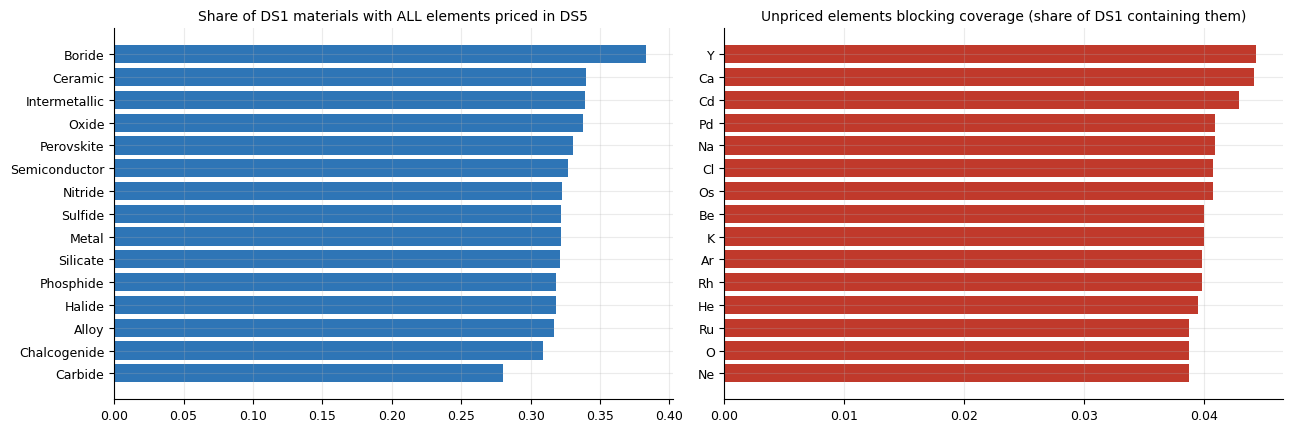

In [18]:
els5 = set(d5.element); sets = [set(A.parse_elements(f)) for f in d1.formula]
full = np.array([s <= els5 for s in sets]); frac = np.array([len(s & els5) / len(s) for s in sets])
from collections import Counter
miss = Counter(e for s in sets for e in (s - els5)); present = Counter(e for s in sets for e in s)
mt = pd.DataFrame({"n_materials_containing": pd.Series(miss)}).sort_values("n_materials_containing", ascending=False).head(15); mt["share_of_DS1"] = mt.n_materials_containing / len(d1)
print(f"DS1 materials with all elements priced: {full.mean():.1%} | mean share of a material's elements that are priced: {frac.mean():.1%}"); display(mt.round(3))
cov = pd.DataFrame({"category": d1.category, "full": full}).groupby("category").full.mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4)); ax[0].barh(cov.index, cov.values, color="#2e75b6"); ax[0].set_title("Share of DS1 materials with ALL elements priced in DS5")
ax[1].barh(mt.index[::-1], mt.share_of_DS1[::-1], color="#c0392b"); ax[1].set_title("Unpriced elements blocking coverage (share of DS1 containing them)")
savefig("C3_element_cost_coverage.png")
note("ds5_ds1_full_coverage", float(full.mean()), "share of DS1 materials with all elements priced in DS5")
note("ds5_ds1_unpriced_top", ", ".join(f"{k}:{v}" for k, v in miss.most_common(5)), "most frequent unpriced elements in DS1 (element:count)")

## C4 · Do element prices (DS5) co-move with commodity prices (DS2)?
Crosswalk (by name, an assumption): Copper→Cu, Aluminium→Al, Nickel→Ni, Iron_Ore→Fe, Cobalt_Index→Co, Lithium_ETF→Li. Monthly returns, lags −3…+3 months.
*Question: is there any lead-lag relationship that would justify using element prices as drivers of commodity risk?*

42 lag tests; BH-significant: 0; max |r| = 0.220; contemporaneous (lag 0) r: {'Copper-Cu': -0.091, 'Aluminium-Al': -0.063, 'Nickel-Ni': 0.052, 'Iron_Ore-Fe': 0.111, 'Cobalt_Index-Co': -0.152, 'Lithium_ETF-Li': -0.046}


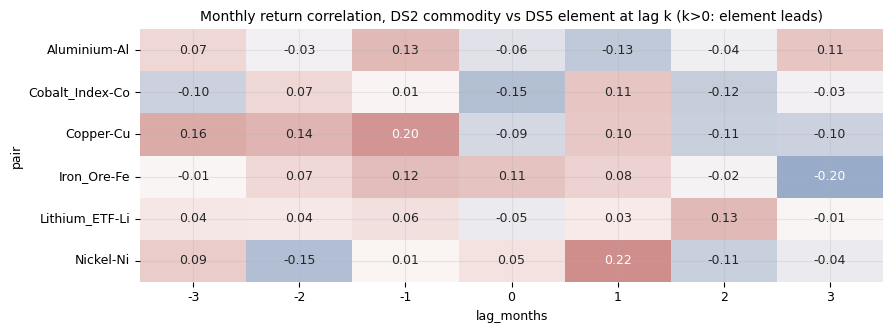

In [19]:
xw = {"Copper": "Cu", "Aluminium": "Al", "Nickel": "Ni", "Iron_Ore": "Fe", "Cobalt_Index": "Co", "Lithium_ETF": "Li"}
mret = np.log(px.resample("ME").last()).diff(); mret.index = mret.index.to_period("M"); er = p5.pct_change(); er.index = er.index.to_period("M")
rows = []
for c, e_ in xw.items():
    if e_ not in er.columns: continue
    for k in range(-3, 4):
        a, b = mret[c], er[e_].shift(-k); j = pd.concat([a, b], axis=1).dropna()
        if j.iloc[:, 1].nunique() < 3: continue
        r, p = sps.pearsonr(j.iloc[:, 0], j.iloc[:, 1]); rows.append({"pair": f"{c}-{e_}", "lag_months": k, "r": r, "p": p, "n": len(j)})
lg = pd.DataFrame(rows); lg["q"] = S.bh_fdr(lg.p); lg.to_csv(TAB / "C4_ds2_ds5_leadlag.csv", index=False)
print(f"{len(lg)} lag tests; BH-significant: {int((lg.q<.05).sum())}; max |r| = {lg.r.abs().max():.3f}; contemporaneous (lag 0) r: {lg[lg.lag_months==0].set_index('pair').r.round(3).to_dict()}")
fig, ax = plt.subplots(figsize=(9, 3.4)); sns.heatmap(lg.pivot(index="pair", columns="lag_months", values="r"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.4, vmax=.4, ax=ax, cbar=False); ax.set_title("Monthly return correlation, DS2 commodity vs DS5 element at lag k (k>0: element leads)")
savefig("C4_ds2_ds5_leadlag.png")
note("ds2_ds5_leadlag_sig", int((lg.q < .05).sum()), "DS2-DS5 lead/lag correlations significant after BH")
note("ds2_ds5_max_abs_r", float(lg.r.abs().max()), "largest |monthly return correlation| between a DS2 commodity and its DS5 element")

# PART D — Exposure (EAD) and loss severity (LGD)
## D1 · Infrastructure exposure in DS3
*Question: how large and how concentrated is exposure, and is financial leverage related to asset risk?*

,count,mean,std,min,50%,90%,99%,max
replacement_cost_M,5000.0,0.682,0.714,0.020,0.470,1.420,3.470,10.890
loan_outstanding_M,5000.0,0.375,0.421,0.010,0.250,0.790,2.130,7.550
ltv,5000.0,0.549,0.146,0.200,0.547,0.750,0.800,1.000
cost_per_sqft,5000.0,274.602,72.400,138.249,275.441,375.205,397.767,404.412


{'total_replacement_M': np.float64(3409.4), 'total_loan_M': np.float64(1876.8)}


,replacement_cost_M,loan_outstanding_M
Gini,0.455,0.475
top1%_share,0.070,0.078
top5%_share,0.216,0.230
top10%_share,0.335,0.353


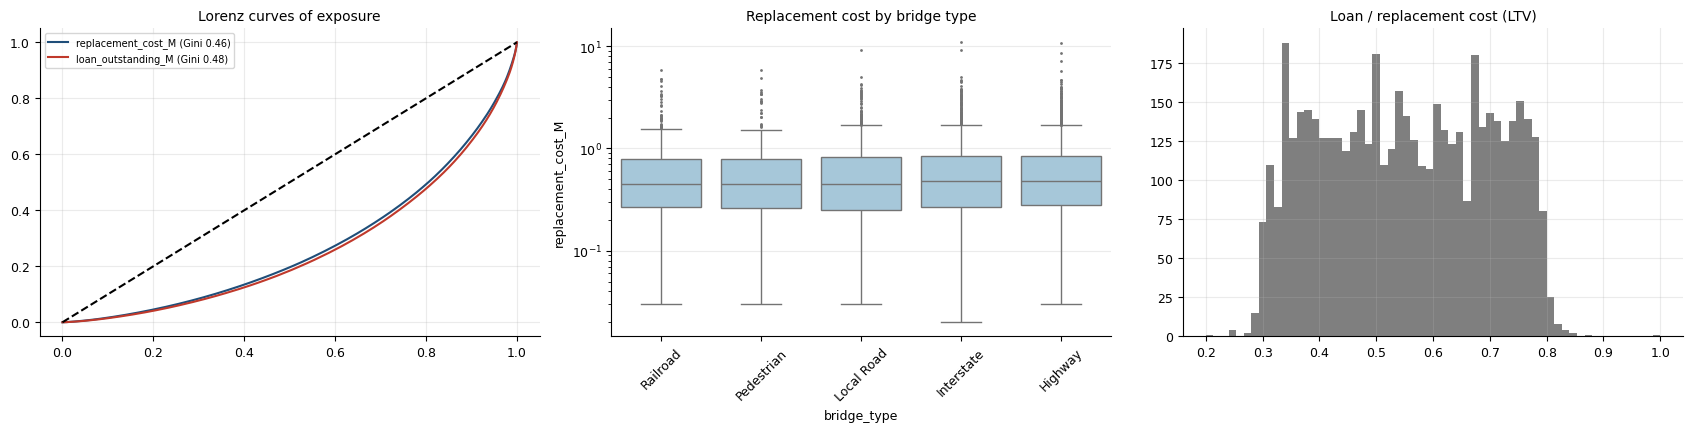

Spearman of LTV with risk drivers: {'condition_rating': -0.005, 'age_years': 0.017, 'corrosion_rate_mm_yr': -0.007, 'replacement_cost_M': 0.007, 'adt': -0.006}
Spearman(replacement cost, deck area) = 0.939 | eta2 of log cost-per-sqft by bridge_type: 0.001 | by material: 0.002


In [20]:
d3 = d3.copy(); d3["ltv"] = d3.loan_outstanding_M / d3.replacement_cost_M; d3["cost_per_sqft"] = d3.replacement_cost_M * 1e6 / d3.deck_area_sqft
d3["thick_frac"] = d3.remaining_thickness_mm / d3.original_thickness_mm
ex = pd.DataFrame({"replacement_cost_M": d3.replacement_cost_M, "loan_outstanding_M": d3.loan_outstanding_M, "ltv": d3.ltv, "cost_per_sqft": d3.cost_per_sqft}).describe(percentiles=[.5, .9, .99]).T.round(3); display(ex)
tot = {"total_replacement_M": d3.replacement_cost_M.sum(), "total_loan_M": d3.loan_outstanding_M.sum()}; print({k: round(v, 1) for k, v in tot.items()})
conc = pd.DataFrame({v: {"Gini": S.gini(d3[v]), "top1%_share": S.top_share(d3[v], .01), "top5%_share": S.top_share(d3[v], .05), "top10%_share": S.top_share(d3[v], .10)} for v in ("replacement_cost_M", "loan_outstanding_M")}).round(3); conc.to_csv(TAB / "D1_exposure_concentration.csv"); display(conc)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for v, c_ in (("replacement_cost_M", "#1f4e79"), ("loan_outstanding_M", "#c0392b")): x_, y_ = S.lorenz_curve(d3[v]); ax[0].plot(x_, y_, label=f"{v} (Gini {S.gini(d3[v]):.2f})", color=c_)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].legend(fontsize=7); ax[0].set_title("Lorenz curves of exposure")
order = d3.groupby("bridge_type").replacement_cost_M.median().sort_values().index; sns.boxplot(data=d3, x="bridge_type", y="replacement_cost_M", order=order, ax=ax[1], color="#9ecae1", fliersize=1); ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Replacement cost by bridge type")
ax[2].hist(d3.ltv, bins=60, color="#7f7f7f"); ax[2].set_title("Loan / replacement cost (LTV)")
savefig("D1_exposure.png")
sp = pd.Series({c: S.spearman_with_p(d3[c], d3.ltv)[0] for c in ["condition_rating", "age_years", "corrosion_rate_mm_yr", "replacement_cost_M", "adt"]}).round(3)
print("Spearman of LTV with risk drivers:", sp.to_dict()); print("Spearman(replacement cost, deck area) =", round(sps.spearmanr(d3.replacement_cost_M, d3.deck_area_sqft)[0], 3), "| eta2 of log cost-per-sqft by bridge_type:", round(S.eta_squared(np.log(d3.cost_per_sqft), d3.bridge_type), 3), "| by material:", round(S.eta_squared(np.log(d3.cost_per_sqft), d3.material), 3))
note("ds3_total_replacement_M", float(tot["total_replacement_M"]), "total replacement cost of the DS3 bridge book (USD M)")
note("ds3_total_loan_M", float(tot["total_loan_M"]), "total loan outstanding of the DS3 bridge book (USD M)")
note("ds3_gini_replacement", float(conc.loc["Gini", "replacement_cost_M"]), "Gini of replacement cost")
note("ds3_top5pct_share_replacement", float(conc.loc["top5%_share", "replacement_cost_M"]), "share of replacement cost held by the top 5% of bridges")
note("ds3_ltv_median", float(d3.ltv.median()), "median loan-to-replacement-cost ratio")
note("ds3_ltv_vs_rating_rho", float(sp["condition_rating"]), "Spearman(LTV, condition rating)")

## D2 · Does the insurance premium reflect risk?
*Question: the implied premium rate (premium / replacement cost) is the only market-style price of risk in DS3. Does it respond to condition, age, corrosion or material? If so it can validate model expected loss; if not, it is only an order-of-magnitude benchmark.*

{'count': 5000.0, 'mean': 165.53, 'std': 49.39, 'min': 75.0, '5%': 88.24, '50%': 165.79, '95%': 242.11, 'max': 266.67}
Spearman of premium rate with drivers: {'condition_rating': 0.008, 'age_years': -0.001, 'corrosion_rate_mm_yr': 0.009, 'thick_frac': 0.011, 'adt': 0.001, 'replacement_cost_M': -0.006, 'loan_outstanding_M': 0.0, 'ltv': 0.019}
η² of premium rate by group: {'material': 0.002, 'bridge_type': 0.0, 'corrosion_environment': 0.0, 'location': 0.002, 'condition_rating': 0.002}
Spearman(premium $K, replacement cost) = 0.929


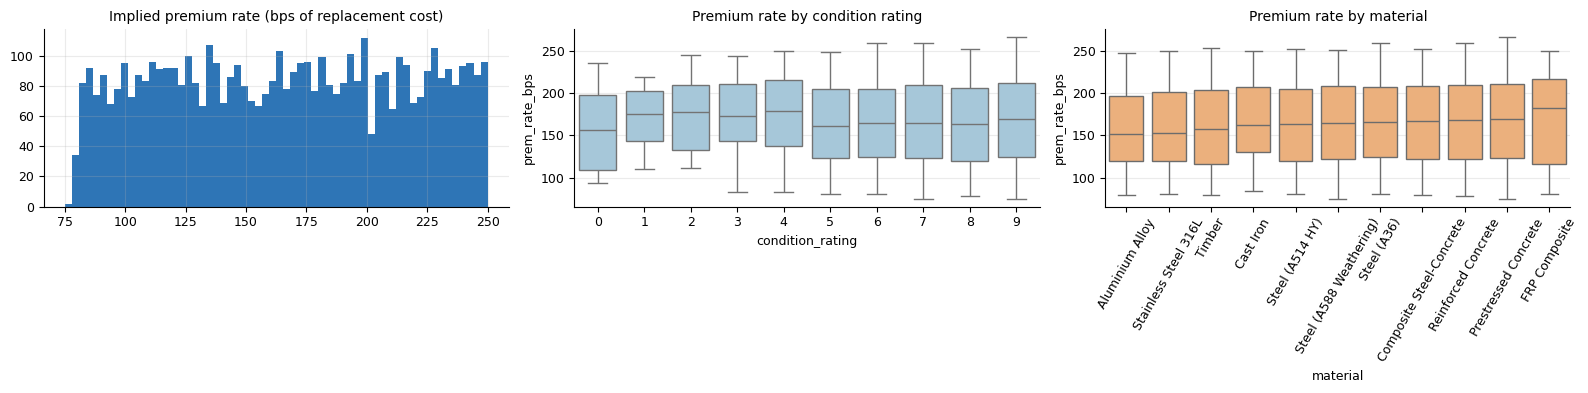

In [21]:
d3["prem_rate_bps"] = d3.insurance_premium_K_yr * 1e3 / (d3.replacement_cost_M * 1e6) * 1e4
print(d3.prem_rate_bps.describe(percentiles=[.05, .5, .95]).round(2).to_dict())
dr = pd.Series({c: S.spearman_with_p(d3[c], d3.prem_rate_bps)[0] for c in ["condition_rating", "age_years", "corrosion_rate_mm_yr", "thick_frac", "adt", "replacement_cost_M", "loan_outstanding_M", "ltv"]}).round(3)
et = pd.Series({g: S.eta_squared(d3.prem_rate_bps, d3[g]) for g in ["material", "bridge_type", "corrosion_environment", "location", "condition_rating"]}).round(3)
print("Spearman of premium rate with drivers:", dr.to_dict()); print("η² of premium rate by group:", et.to_dict())
print("Spearman(premium $K, replacement cost) =", round(sps.spearmanr(d3.insurance_premium_K_yr, d3.replacement_cost_M)[0], 3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4)); ax[0].hist(d3.prem_rate_bps.clip(upper=d3.prem_rate_bps.quantile(.995)), bins=60, color="#2e75b6"); ax[0].set_title("Implied premium rate (bps of replacement cost)")
sns.boxplot(data=d3, x="condition_rating", y="prem_rate_bps", ax=ax[1], color="#9ecae1", fliersize=1); ax[1].set_title("Premium rate by condition rating")
sns.boxplot(data=d3, x="material", y="prem_rate_bps", ax=ax[2], color="#fdae6b", fliersize=1, order=d3.groupby("material").prem_rate_bps.median().sort_values().index); ax[2].tick_params(axis="x", rotation=60); ax[2].set_title("Premium rate by material")
savefig("D2_premium.png")
note("ds3_premium_rate_median_bps", float(d3.prem_rate_bps.median()), "median implied annual premium rate (bps of replacement cost)")
note("ds3_premium_vs_rating_rho", float(dr["condition_rating"]), "Spearman(premium rate, condition rating)")
note("ds3_premium_vs_corrosion_rho", float(dr["corrosion_rate_mm_yr"]), "Spearman(premium rate, corrosion rate)")
note("ds3_premium_eta2_material", float(et["material"]), "share of premium-rate variance explained by material")

## D3 · Loss severity (LGD) in DS6
*Questions: what is the empirical distribution of loss ratio; does it depend on severity class only, or on structure, material, environment, age and corrosion? What does capping at 1 change?*

,uncapped,capped_at_1
count,2000.0000,2000.0000
mean,0.2996,0.2905
std,0.2967,0.2694
min,0.0253,0.0253
50%,0.2058,0.2058
90%,0.7083,0.7083
99%,1.3550,1.0000
max,1.4645,1.0000


,count,min,median,mean,max,"KS_vs_uniform_on_[min,max]",KS_p
severity,,,,,,,
Minor,622,0.0253,0.0486,0.0495,0.0749,0.0361,0.3820
Moderate,705,0.1004,0.1999,0.2003,0.3000,0.0160,0.9927
Major,477,0.2501,0.4896,0.5019,0.7495,0.0250,0.9185
Catastrophic,196,0.5165,0.9483,0.9580,1.4645,0.0866,0.0998


Loss ratio explained (Kruskal ε²) by:


,epsilon2,p
driver,,
severity,0.8998,0.0000
structure_type,0.0000,0.3998
material,0.0027,0.1195
corrosion_environment,0.0046,0.0038
failure_mode,0.0000,0.9580


Within-severity Spearman of loss ratio with drivers:


,rho_age,rho_corrosion
severity,,
Minor,-0.011,-0.009
Moderate,0.003,0.041
Major,0.063,-0.028
Catastrophic,0.056,-0.035


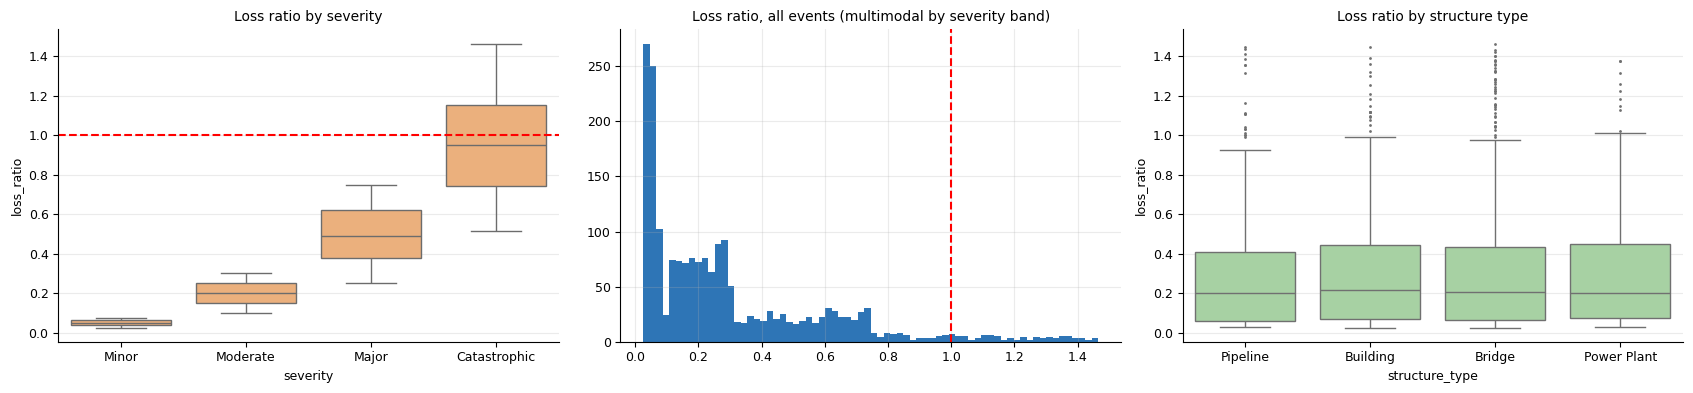

In [22]:
so = ["Minor", "Moderate", "Major", "Catastrophic"]; d6 = d6.copy(); d6["lr_cap"] = d6.loss_ratio.clip(upper=1)
q = pd.DataFrame({"uncapped": d6.loss_ratio.describe(percentiles=[.5, .9, .99]), "capped_at_1": d6.lr_cap.describe(percentiles=[.5, .9, .99])}).round(4); display(q)
sev = d6.groupby("severity").loss_ratio.agg(["count", "min", "median", "mean", "max"]).loc[so].round(4)
ks = {s: sps.kstest((d6.loss_ratio[d6.severity == s] - d6.loss_ratio[d6.severity == s].min()) / (d6.loss_ratio[d6.severity == s].max() - d6.loss_ratio[d6.severity == s].min()), "uniform") for s in so}
sev["KS_vs_uniform_on_[min,max]"] = [ks[s].statistic for s in so]; sev["KS_p"] = [ks[s].pvalue for s in so]; sev.round(4).to_csv(TAB / "D3_loss_ratio_by_severity.csv"); display(sev.round(4))
tests = [("severity", d6.severity), ("structure_type", d6.structure_type), ("material", d6.material), ("corrosion_environment", d6.corrosion_environment), ("failure_mode", d6.failure_mode)]
kt = pd.DataFrame([dict(zip(["epsilon2", "p"], S.kruskal_epsilon2(d6.loss_ratio, g)), driver=n) for n, g in tests]).set_index("driver").round(4)
within = d6.groupby("severity").apply(lambda d: pd.Series({"rho_age": S.spearman_with_p(d.age_at_event_years, d.loss_ratio)[0], "rho_corrosion": S.spearman_with_p(d.corrosion_rate_mm_yr, d.loss_ratio)[0]})).loc[so].round(3)
print("Loss ratio explained (Kruskal ε²) by:"); display(kt); print("Within-severity Spearman of loss ratio with drivers:"); display(within)
fig, ax = plt.subplots(1, 3, figsize=(17, 4)); sns.boxplot(data=d6, x="severity", y="loss_ratio", order=so, ax=ax[0], color="#fdae6b", fliersize=1); ax[0].axhline(1, color="r", ls="--"); ax[0].set_title("Loss ratio by severity")
ax[1].hist(d6.loss_ratio, bins=70, color="#2e75b6"); ax[1].axvline(1, color="r", ls="--"); ax[1].set_title("Loss ratio, all events (multimodal by severity band)")
sns.boxplot(data=d6, x="structure_type", y="loss_ratio", ax=ax[2], color="#a1d99b", fliersize=1); ax[2].set_title("Loss ratio by structure type")
savefig("D3_loss_ratio.png")
note("ds6_lgd_mean_uncapped", float(d6.loss_ratio.mean()), "mean loss ratio (uncapped)")
note("ds6_lgd_mean_capped", float(d6.lr_cap.mean()), "mean loss ratio capped at 1")
note("ds6_lgd_share_gt1", float((d6.loss_ratio > 1).mean()), "share of events with loss ratio > 1")
note("ds6_lgd_eps2_severity", float(kt.loc["severity", "epsilon2"]), "share of loss-ratio rank variance explained by severity class")
note("ds6_lgd_eps2_other_max", float(kt.drop("severity").epsilon2.max()), "largest epsilon2 of structure/material/environment/failure mode for loss ratio")
note("ds6_lgd_ks_uniform_max_stat", float(max(v.statistic for v in ks.values())), "largest KS statistic of within-severity loss ratio vs uniform on its observed range")

## D4 · Tail heaviness of event losses and the scale link between DS6 and DS3
*Questions: how heavy are the tails of replacement value and repair cost (Hill index; α < 2 ⇒ infinite variance)? How much of total loss do the largest events carry? Are DS6 bridge replacement values on the same scale as DS3 replacement costs (needed if LGD is applied to DS3 exposure)?*

Hill tail index (stable range k=20..300): repair cost median 1.82 [1.55, 2.20] | replacement value median 2.06 [1.80, 2.38]
Top-10 events = 9.4% of total repair cost; top 1% of events = 14.6%; top 5% = 35.8%; Gini(repair cost) = 0.661
annual aggregate repair cost (USD M): mean=57, sd=11, CV=0.20, max=82 (2011)


,DS3 bridge book replacement_cost (USD),DS6 bridge failures replacement_value (USD)
count,5000.0,1011.0
mean,681870.0,2030624.0
std,713707.0,3800077.0
min,20000.0,42833.0
50%,470000.0,1159727.0
90%,1420000.0,4249631.0
99%,3470200.0,12008141.0
max,10890000.0,66380301.0


median(DS6 bridge replacement value) / median(DS3 replacement cost) = 2.47


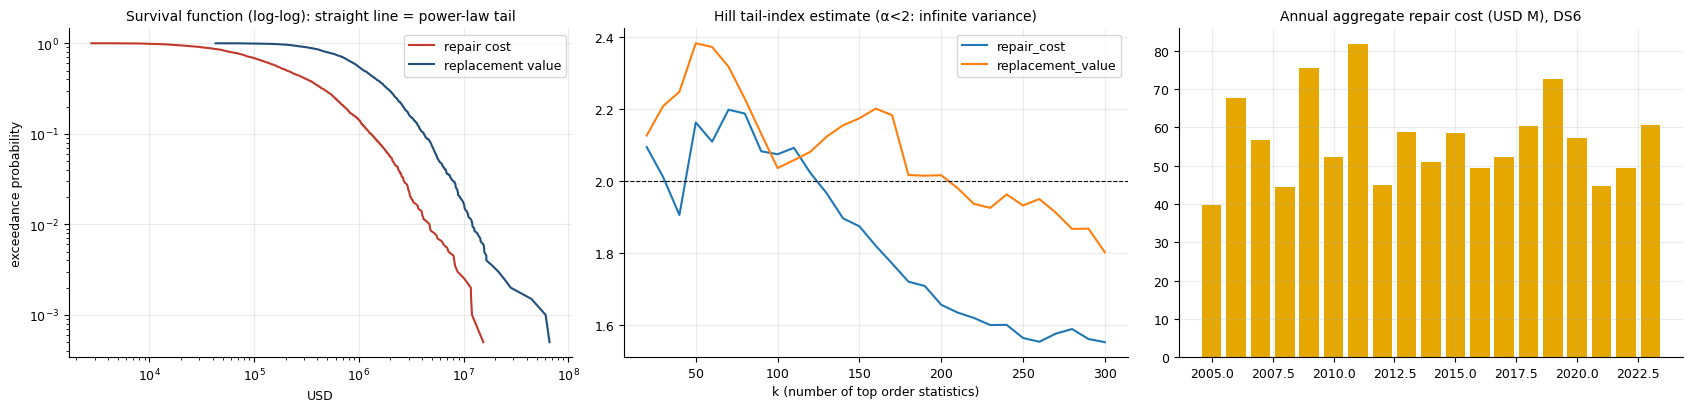

In [23]:
rc, rv_ = d6.repair_cost_USD.values, d6.replacement_value_USD.values; ks_ = np.arange(20, 301, 10)
hill = pd.DataFrame({"repair_cost": [S.hill_estimator(rc, k) for k in ks_], "replacement_value": [S.hill_estimator(rv_, k) for k in ks_]}, index=ks_)
print("Hill tail index (stable range k=20..300): repair cost median %.2f [%.2f, %.2f] | replacement value median %.2f [%.2f, %.2f]" % (hill.repair_cost.median(), hill.repair_cost.min(), hill.repair_cost.max(), hill.replacement_value.median(), hill.replacement_value.min(), hill.replacement_value.max()))
tot_loss = rc.sum(); top10 = np.sort(rc)[::-1][:10].sum() / tot_loss; top1pct = S.top_share(rc, .01); top5pct = S.top_share(rc, .05)
print(f"Top-10 events = {top10:.1%} of total repair cost; top 1% of events = {top1pct:.1%}; top 5% = {top5pct:.1%}; Gini(repair cost) = {S.gini(rc):.3f}")
ann = d6.groupby("event_year").repair_cost_USD.sum() / 1e6
print(f"annual aggregate repair cost (USD M): mean={ann.mean():.0f}, sd={ann.std():.0f}, CV={ann.std()/ann.mean():.2f}, max={ann.max():.0f} ({ann.idxmax()})")
b6 = d6[d6.structure_type == "Bridge"]; scale = pd.DataFrame({"DS3 bridge book replacement_cost (USD)": (d3.replacement_cost_M * 1e6).describe(percentiles=[.5, .9, .99]), "DS6 bridge failures replacement_value (USD)": b6.replacement_value_USD.describe(percentiles=[.5, .9, .99])}).round(0); display(scale)
print("median(DS6 bridge replacement value) / median(DS3 replacement cost) = %.2f" % (b6.replacement_value_USD.median() / (d3.replacement_cost_M.median() * 1e6)))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for v, lab, c_ in ((rc, "repair cost", "#c0392b"), (rv_, "replacement value", "#1f4e79")): x_ = np.sort(v)[::-1]; ax[0].loglog(x_, np.arange(1, len(x_) + 1) / len(x_), label=lab, color=c_)
ax[0].set_xlabel("USD"); ax[0].set_ylabel("exceedance probability"); ax[0].legend(); ax[0].set_title("Survival function (log-log): straight line = power-law tail")
hill.plot(ax=ax[1]); ax[1].axhline(2, color="k", ls="--", lw=.8); ax[1].set_xlabel("k (number of top order statistics)"); ax[1].set_title("Hill tail-index estimate (α<2: infinite variance)")
ax[2].bar(ann.index, ann.values, color="#e6a700"); ax[2].set_title("Annual aggregate repair cost (USD M), DS6")
savefig("D4_loss_tails.png")
note("ds6_hill_alpha_repair_median", float(hill.repair_cost.median()), "median Hill tail index of repair cost (k=20..300)")
note("ds6_top10_share_repair", float(top10), "share of total repair cost from the 10 largest events")
note("ds6_annual_loss_cv", float(ann.std() / ann.mean()), "coefficient of variation of annual aggregate repair cost")
note("scale_ratio_ds6_ds3_median", float(b6.replacement_value_USD.median() / (d3.replacement_cost_M.median() * 1e6)), "median DS6 bridge replacement value / median DS3 replacement cost")

## D5 · Claims and regulatory action
*Question: is there evidence of an insurance retention (small losses unclaimed) or of severity-triggered regulatory response — i.e. structure the loss model must respect?*

,insurance_claim_filed,regulatory_action
severity,,
Minor,0.693,0.000
Moderate,0.726,0.000
Major,0.660,0.564
Catastrophic,0.658,0.648


claim rate by repair-cost decile: min=0.64, max=0.73; Spearman(repair cost, claim filed) = -0.015 (p=0.49)
Cramér's V severity~claim = 0.046 (p=0.067); severity~regulatory action = 0.699 (p=4.41e-212)


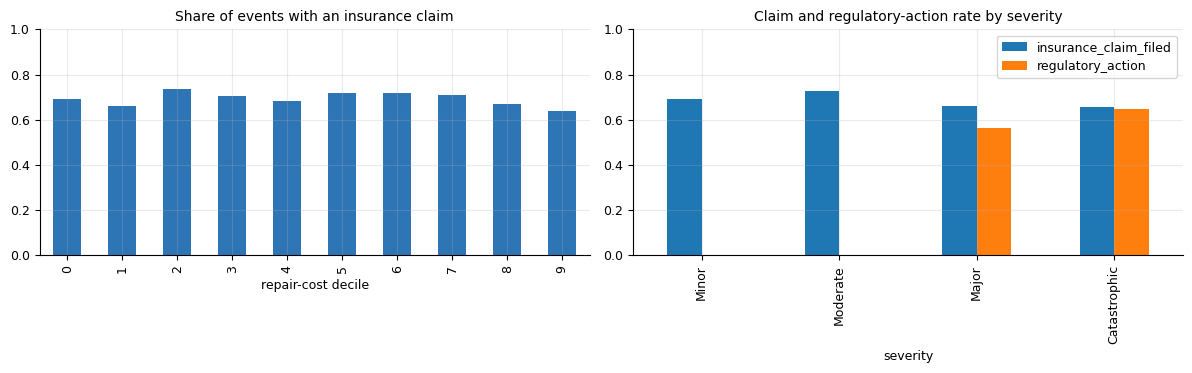

In [24]:
d6["cost_dec"] = pd.qcut(d6.repair_cost_USD.rank(method="first"), 10, labels=False)
cl = d6.groupby("cost_dec").insurance_claim_filed.mean(); cs = d6.groupby("severity")[["insurance_claim_filed", "regulatory_action"]].mean().loc[so].round(3); display(cs)
rho_c = sps.spearmanr(d6.repair_cost_USD, d6.insurance_claim_filed)
print(f"claim rate by repair-cost decile: min={cl.min():.2f}, max={cl.max():.2f}; Spearman(repair cost, claim filed) = {rho_c[0]:+.3f} (p={rho_c[1]:.2f})")
V1 = S.cramers_v(d6.severity, d6.insurance_claim_filed); V2 = S.cramers_v(d6.severity, d6.regulatory_action); print(f"Cramér's V severity~claim = {V1[0]:.3f} (p={V1[2]:.3f}); severity~regulatory action = {V2[0]:.3f} (p={V2[2]:.3g})")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); cl.plot.bar(ax=ax[0], color="#2e75b6"); ax[0].set_ylim(0, 1); ax[0].set_xlabel("repair-cost decile"); ax[0].set_title("Share of events with an insurance claim")
cs.plot.bar(ax=ax[1]); ax[1].set_title("Claim and regulatory-action rate by severity"); ax[1].set_ylim(0, 1)
savefig("D5_claims.png")
note("ds6_claim_rate_overall", float(d6.insurance_claim_filed.mean()), "overall share of failures with an insurance claim")
note("ds6_claim_vs_cost_rho", float(rho_c[0]), "Spearman(repair cost, claim filed): retention would give a positive relation")
note("ds6_regulatory_rate_major_cat", float(d6[d6.severity.isin(["Major", "Catastrophic"])].regulatory_action.mean()), "regulatory-action rate among Major/Catastrophic events")
note("ds6_regulatory_rate_minor_mod", float(d6[d6.severity.isin(["Minor", "Moderate"])].regulatory_action.mean()), "regulatory-action rate among Minor/Moderate events")

## D6 · Order-of-magnitude benchmark: DS6 events × DS3 premiums
This is **not** a validation — it rests on the unproven assumption that the DS3 book is the population exposed to the DS6 bridge failures (Part C5).
It only shows how an implied annual expected loss compares with the premium level, and how sensitive it is to the size of the exposed population.

In [25]:
n_years = d6.event_year.nunique(); n_bridge = int((d6.structure_type == "Bridge").sum()); lgd_cap = d6.lr_cap.mean(); prem = d3.prem_rate_bps.median()
rows = []
for mult in (0.5, 1, 2, 5, 10):
    freq = n_bridge / n_years / (len(d3) * mult); rows.append({"exposed population / DS3 size": mult, "failures per bridge-year": freq, "implied EL (bps of replacement cost)": freq * lgd_cap * 1e4, "median premium (bps)": prem, "premium / implied EL": prem / (freq * lgd_cap * 1e4)})
bm = pd.DataFrame(rows).round(4); bm.to_csv(TAB / "D6_el_vs_premium_benchmark.csv", index=False); display(bm)
print(f"{n_bridge} bridge failures over {n_years} years; mean capped LGD = {lgd_cap:.3f}")
note("bench_failures_per_bridge_year_if_DS3_is_population", float(n_bridge / n_years / len(d3)), "implied annual failure frequency if DS3 (5,000 bridges) were the exposed population")
note("bench_implied_EL_bps_if_DS3_is_population", float(n_bridge / n_years / len(d3) * lgd_cap * 1e4), "implied annual EL (bps of replacement cost) under that assumption, mean capped LGD")
note("bench_premium_over_EL_multiple", float(prem / (n_bridge / n_years / len(d3) * lgd_cap * 1e4)), "median premium rate / implied EL under that assumption")

,exposed population / DS3 size,failures per bridge-year,implied EL (bps of replacement cost),median premium (bps),premium / implied EL
0,0.5,0.0213,61.8394,165.7895,2.6810
1,1.0,0.0106,30.9197,165.7895,5.3619
2,2.0,0.0053,15.4598,165.7895,10.7239
3,5.0,0.0021,6.1839,165.7895,26.8097
4,10.0,0.0011,3.0920,165.7895,53.6194


1011 bridge failures over 19 years; mean capped LGD = 0.291


## Key computed findings (printed from the run; saved to `outputs/tables/financial_eda_key_findings.csv`)

In [26]:
kf = pd.DataFrame([{"finding": k, "value": (round(v["value"], 4) if isinstance(v["value"], float) else v["value"]), "meaning": v["meaning"]} for k, v in KEY.items()])
kf.to_csv(TAB / "financial_eda_key_findings.csv", index=False); pd.set_option("display.max_colwidth", 120); display(kf)

,finding,value,meaning
0,ds2_mean_ann_vol,0.3253,mean annualised volatility across commodities
1,ds2_max_abs_excess_kurtosis,0.141,largest |excess kurtosis| of daily returns (0 = normal tails)
2,ds2_JB_reject_count,0,"commodities where normality is rejected (Jarque-Bera p<0.05), out of 8"
3,ds2_vol_max_over_min_annual,1.2432,largest ratio of max to min annual volatility within a commodity
4,ds2_levene_reject_count,1,commodities with significantly different variance across years (Levene p<0.05)
5,ds2_common_vol_regime_corr,-0.017,mean pairwise correlation of rolling-vol series
6,ds2_ljungbox_returns_reject,0,"commodities with significant return autocorrelation (BH q<0.05), of 8"
7,ds2_ljungbox_squared_reject,0,commodities with significant volatility clustering in squared returns (BH q<0.05)
8,ds2_arch_lm_reject,0,commodities where ARCH-LM rejects constant conditional variance (BH q<0.05)
9,ds2_mean_abs_lag1_autocorr,0.0138,mean |lag-1 autocorrelation| of daily returns


## What the financial EDA establishes (every number is from the cells above)

### Part A — DS2 commodity markets
1. **Returns are close to Gaussian and homoskedastic.** |Excess kurtosis| ≤ 0.14, Jarque–Bera rejects normality for 0 of 8, and the share of |z| > 3 days is 0.17–0.38% against 0.27% for a normal. Mean annualised volatility is 32.5%. Historical 99% VaR / ES equal the normal-implied values to within a few percent (median ratios 1.01 / 1.02; range 0.99–1.04 for VaR).
2. **No volatility clustering or serial dependence.** Ljung–Box on returns: 0/8; on squared returns: 0/8; ARCH-LM: 0/8; mean |lag-1 autocorrelation| = 0.014. Annual volatility varies by at most 1.24× within a commodity (Levene rejects for 1/8) and rolling volatilities are uncorrelated across commodities (−0.02). **GARCH/EWMA volatility scaling is not supported by this history.**
3. **There is a genuine, shared calendar seasonality — the one clear structure in DS2.** The eight month-profiles correlate at 0.46; the equal-weight average of all commodities differs by month at Kruskal p ≈ 8×10⁻¹⁴ (weakest: July −23, May −18, June −15 bp/day; strongest: November +20, March +16, February +16 bp/day); best-minus-worst month amplitude is 48–90 bp/day (median 65) against a monthly-mean standard error of ≈10–18 bp. Four commodities are individually significant (Aluminium, Copper, Nickel, Steel_HRC); there is no weekday effect (0/8).
4. **That seasonality is what breaks √time scaling.** Raw variance ratios exceed 1 at longer horizons (mean VR(63) = 1.23; Copper 1.57, z = 3.4); after removing calendar-month means the mean VR(63) falls to 0.93. For a 21-day horizon the empirical 99% VaR differs from 1-day VaR × √21 by up to ≈ +20% (Copper 0.202 vs 0.168) and −12% (Iron_Ore) — so multi-week horizon risk should be computed from empirical/seasonal horizon returns, not scaled.
5. **Price levels behave like random walks with negative-to-flat drifts and deep drawdowns.** A unit root in log price is not rejected for 6/8 (returns stationary 8/8); worst drawdowns are −63% to −86% (RareEarth_ETF −86.2%), the worst drawdown never recovered within the sample for 5/8, and each series is below its running peak 97–99% of the time.
6. **Diversification is almost perfect in-sample.** Mean pairwise correlation 0.0075 (max |0.038|), 0/28 pairs significant, effective number of independent assets 7.99 of 8, largest eigenvalue 1.06, joint lower-tail days 7 vs 7.7 expected under independence. A portfolio VaR built on these correlations will show near-maximal diversification; the engine will therefore also report a **correlation-stress variant** rather than present the in-sample figure alone.
7. **Auxiliary fields:** `term_spread` has no forecasting content (0/24 significant, max |ρ| = 0.10) and inconsistent scale across commodities (std 4.9–161.8; Nickel 162) — within-commodity standardisation only. Volume is unrelated to |return| (mean ρ = −0.01). The OHLC range is far narrower than close-to-close volatility implies (Parkinson/close-to-close = 0.28–0.51, median 0.39), so **high/low must not be used for volatility estimators (Parkinson, ATR)**.

### Part B — DS4 cross-domain features
1. **Mostly commodity-level attributes that drift slowly:** 81% of MQI variance, 98% of supply-disruption-probability variance and 99.9% of Herfindahl variance is *between* commodities. Within a commodity they are highly persistent but stationary (lag-1 autocorrelation 0.99 / 0.98; ADF rejects a unit root for all 8; half-lives ≈ 47–86 days for MQI and 26–46 days for supply-disruption probability).
2. **They carry no demonstrable predictive information.** 0/40 feature→future-return tests (max |ρ| = 0.099), 0/10 feature→future-volatility tests (max |ρ| = 0.058), 0/20 contemporaneous tests and 0/6 stress-state event-study contrasts (largest |difference| 0.16 sd) survive FDR; the smallest q-value across all 70 correlation tests is 0.083.

### Part C — DS5 element prices
1. **Element prices are almost static:** over 11 years the largest max/min price ratio of any of the 40 elements is 1.35, median annualised volatility is 3.8% (the supplied `monthly_return` implies ≈19× more), 3 elements have an unchanged price in more than half of the months, and there is no co-movement (mean pairwise correlation −0.001; 0 correlation eigenvalues above the noise edge) and no lead–lag relation to the DS2 commodities (0 of 42 significant, max |r| = 0.22).
2. **Coverage of DS1 is limited:** only 32.6% of DS1 materials have all their elements priced; the most frequent unpriced elements are Y (244 materials), Ca (243), Cd (236), Pd (225), Na (225). DS5 therefore supports **static element-cost levels for part of DS1**, not dynamic commodity-risk drivers.

### Part D — Exposure and loss severity
1. **Exposure (EAD):** the DS3 book has total replacement cost USD 3,409 M and loans of USD 1,877 M (median LTV 0.55); concentration is moderate (Gini 0.455; top 5% of bridges hold 21.6% of replacement cost). LTV is unrelated to condition (ρ = −0.005).
2. **Premiums are not risk-based:** implied premium rate has median 166 bps of replacement cost and is unrelated to condition rating (ρ = +0.008), corrosion (+0.009) or material (η² = 0.002) — it cannot be used to validate model expected losses, only as an order-of-magnitude reference.
3. **Loss given failure (LGD):** mean loss ratio 0.300 (0.291 capped at 1; 4.25% of events exceed 1). The **severity class explains 90% of the loss-ratio rank variance**; structure type, material, environment and failure mode each explain ≤ 0.5%, and within a severity class the loss ratio is uncorrelated with age and corrosion (|ρ| ≤ 0.063). Within each class it is compatible with a uniform distribution over the class's range (KS p = 0.38 / 0.99 / 0.92 / 0.10; ranges taken from the observed minimum and maximum, so the test is slightly generous).
4. **Tail heaviness is borderline, not extreme:** Hill index of repair cost 1.82 (range 1.55–2.20 over k = 20–300) and of replacement value 2.06 (1.80–2.38) — near the infinite-variance boundary but unstable; the 10 largest events carry 9.4% of total repair cost, the top 5% carry 35.8% (Gini 0.66). Annual aggregate repair cost averages USD 57 M with CV 0.20 (consistent with the Poisson-like event counts found in notebook 02).
5. **Scale:** DS6 bridge replacement values are 2.5× the DS3 median, so LGD must be applied as a **ratio**, never as an absolute amount.
6. **Claims and regulation:** claims are filed for 69% of events with no relation to the size of the loss (ρ = −0.015) — no visible insurance retention/deductible; regulatory action occurs for 59% of Major/Catastrophic events and 0% of Minor/Moderate.
7. **Order-of-magnitude benchmark (assumption-dependent):** if DS3 were the exposed population, the DS6 bridge failures imply 1.06% failures per bridge-year and an expected loss of ≈ 31 bps of replacement cost per year — about 5.4× lower than the median premium. If the true exposed population were 0.5×–10× the DS3 book, the implied EL would range from ≈ 62 to ≈ 3 bps. This sensitivity band is what the risk engine must carry for PD calibration.

### Consequences for the risk engine
* **Commodity risk:** use historical simulation (normal and historical VaR coincide in-sample), report ES alongside, compute multi-week horizons from empirical/seasonal horizon returns, and **add explicit stress overlays** (workbook scenarios, correlation stress) because the 11-year history contains neither fat tails nor co-movement.
* **DS4 and DS5 are descriptive, not predictive:** MQI/supply probability can parameterise scenario severity *per commodity* (their variance is mostly between commodities) but must not be presented as return/volatility forecasters; element prices supply static cost levels only.
* **Credit-style chain:** EAD from DS3 replacement cost / loan; LGD as the severity mixture with class-wise ranges (ratio-based, capped and uncapped variants); event frequency Poisson-like. PD remains the single calibrated-proxy element, with the sensitivity band above.